# Actividades 3 y 4. Preparación de datos, modelo base y regresión

**Actividad 3:** Proyecto de Visualización de Datos con Herramientas Básicas  
**Actividad 4:** Análisis de Regresión y Visualización Avanzada  
**Proyecto integrador:** fase 2, preprocesamiento, ingeniería de variables, partición y modelo base  
**Autor:** Julián Andrés Lasso Figueroa  
**Correo institucional:** jlasso96@unisalle.edu.co  
**Programa:** Maestría en Inteligencia Artificial, Universidad de La Salle  
**Asignatura:** Ciencia de Datos, Unidad 2, herramientas de visualización avanzada  
**Docente:** Fabián Camilo Castro Riveros  
**Fecha:** noviembre de 2026

---

## 0. Planteamiento y configuración

### 0.1. Pregunta y objetivos de esta fase

La fase 1 formuló el problema y describió el Saber 11 de 2022-2. Esta fase prepara los datos para modelar y fija los umbrales que las fases siguientes deben superar. Responde a la pregunta secundaria de regresión del proyecto:

- **S1.** ¿Cuánto del puntaje global explican las condiciones del hogar (estrato, educación de los padres, internet, computador y demás bienes) y del colegio (naturaleza, zona, jornada y departamento), sin usar los puntajes por área ni el de inglés?

Y lo hace con cuatro objetivos de trabajo, que alimentan el objetivo específico E1 del proyecto (estimar, a más tardar el 14 de noviembre de 2026, la proporción de la varianza del puntaje global que explican el hogar y el colegio):

1. Diagnosticar el mecanismo de los faltantes antes de imputar y elegir la imputación, el tratamiento de los atípicos y la especificación de la regresión con el error de validación, no con el de prueba.
2. Construir cuatro variables derivadas con respaldo en el dominio y un `Pipeline` que codifique y escale sin fuga de datos.
3. Partir los datos en entrenamiento, validación y prueba (70/15/15, estratificado por la naturaleza del colegio) de forma recuperable sin identificador, y fijar con una prueba de tiempo la muestra para los algoritmos costosos de la fase 3.
4. Ajustar los modelos base y la regresión simple y múltiple en statsmodels, scikit-learn y R, revisar sus supuestos y evaluarlos una sola vez en prueba.

Cada cifra que cita el informe sale de una salida de este cuaderno y se exporta a `resultados/cifras-fase-2.tex`.

### 0.2. Entorno

El cuaderno corre con el entorno del repositorio (`uv sync`) y usa el paquete `saber11` para las reglas de limpieza, la partición, los transformadores y el registro de cifras. Antes de ejecutarlo hay que correr `uv run python -m saber11.intermedios` y `Rscript src/r/fase-2.R`, porque la paridad con R lee la salida de ese script (el orden completo está en el `README.md`).

In [1]:
import json
import platform
import re
import time
import unicodedata
from collections import Counter
from importlib.metadata import version
from itertools import combinations

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
from IPython.display import Image, display
from matplotlib.artist import Artist
from matplotlib.colors import LogNorm
from scipy import stats
from sklearn.cluster import AgglomerativeClustering
from sklearn.linear_model import HuberRegressor, LinearRegression, LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_class_weight
import statsmodels.formula.api as smf
import statsmodels.stats.api as sms

from saber11 import datos, graficos, intermedios, limpieza, modelos, particion
from saber11 import variables as v
from saber11.cifras import Cifras, en_espanol
from saber11.comprobaciones import Comprobaciones

print(f"{'Python':<14}{platform.python_version()}")
for paquete in ("pandas", "numpy", "scipy", "scikit-learn", "statsmodels", "matplotlib", "seaborn", "plotly", "kaleido"):
    print(f"{paquete:<14}{version(paquete)}")

Python        3.13.15
pandas        3.1.1
numpy         2.5.4
scipy         1.18.1
scikit-learn  1.9.1
statsmodels   0.15.0
matplotlib    3.11.2
seaborn       0.13.2
plotly        7.1.0
kaleido       1.5.0


### 0.3. Estilo, rutas, cifras y comprobaciones

Las figuras conservan la estética de la fase 1 (`saber11.graficos`). Las rutas parten de la raíz del repositorio y se imprimen relativas a ella. `comprobar` detiene el cuaderno si una condición falla, y el registro de evaluaciones en prueba empieza vacío en cada ejecución: la prueba se usa una sola vez por modelo, al final (§14), y ninguna decisión de este cuaderno la lee.

In [2]:
graficos.aplicar_estilo()
RAIZ = datos.RAIZ_PROYECTO
RUTA_FIGURAS = RAIZ / "figuras" / "fase-2"
RUTA_RESULTADOS = RAIZ / "resultados"
RUTA_PRUEBA = RUTA_RESULTADOS / "evaluaciones-prueba.json"
FUENTE = "Fuente: ICFES, Saber 11 2022-2 (datos.gov.co), conjunto de entrenamiento."

figuras = graficos.Figuras(RUTA_FIGURAS)
control = Comprobaciones()
comprobar = control.comprobar
cifras = Cifras()
cifra = cifras.cifra
modelos.iniciar_registro_prueba(RUTA_PRUEBA)


def relativa(ruta):
    """Ruta relativa a la raíz del repositorio, para no imprimir rutas locales."""
    return ruta.relative_to(RAIZ).as_posix()


def nombre_macro(columna: str) -> str:
    """Sufijo de macro de LaTeX (solo letras, sin tildes) a partir del nombre de una columna."""
    sin_tildes = unicodedata.normalize("NFKD", columna).encode("ascii", "ignore").decode()
    return "".join(parte.capitalize() for parte in sin_tildes.lower().replace(" ", "_").split("_"))


def porcentaje(parte: float, total: float) -> float:
    return 100 * parte / total


def formatear(valor: object, decimales: int) -> object:
    """Número con coma decimal; los enteros, sin decimales."""
    if isinstance(valor, (bool, np.bool_)) or not isinstance(valor, (int, float, np.integer, np.floating)) or pd.isna(valor):
        return valor
    return en_espanol(valor, 0 if float(valor).is_integer() else decimales)


def tabla(marco: pd.DataFrame, decimales: int = 2) -> None:
    """Imprime una tabla con coma decimal."""
    print(marco.to_string(formatters={c: (lambda x, d=decimales: formatear(x, d)) for c in marco.columns}))


print(f"Figuras en {relativa(RUTA_FIGURAS)}; cifras y registro de prueba en {relativa(RUTA_RESULTADOS)}")

Figuras en figuras/fase-2; cifras y registro de prueba en resultados


## 1. Punto de partida

La fase 1 dejó el recorte de modelado (los estudiantes con resultado publicado del periodo 2022-2, sin duplicados) y un diagnóstico de calidad: faltantes concentrados en las variables del hogar y en dos del colegio, cuatro puntajes globales en cero, fechas de nacimiento imposibles y dos codificaciones que hay que armonizar. Aquí no se repite la exploración: se parte de esos hallazgos y se resuelve cada uno.

In [3]:
recorte = pd.read_parquet(datos.RECORTE_MODELADO)
fase_1 = json.loads((RUTA_RESULTADOS / "cifras-fase-1.json").read_text(encoding="utf-8"))
filas_recorte = len(recorte)
print(f"Recorte de modelado: {en_espanol(filas_recorte)} filas y {recorte.shape[1]} columnas")
comprobar("El recorte tiene las filas que fijó la fase 1", filas_recorte == fase_1["filasModelado"]["valor"])
cifra("filasRecorte", filas_recorte)

Recorte de modelado: 532.566 filas y 27 columnas
[ok] El recorte tiene las filas que fijó la fase 1


'532.566'

## 2. Exclusiones e incoherencias

Solo se excluyen filas con reglas fijas, que no aprenden nada de los datos y por eso pueden aplicarse antes de partir sin filtrar información de validación ni de prueba. Hay dos: la fila sin datos del colegio, que no puede estratificarse por naturaleza, y los puntajes globales en cero, que sin la hoja de respuestas no se distinguen de una prueba en blanco. Las fechas de nacimiento imposibles no justifican borrar la fila, porque el resto del registro es válido: pasan a faltante y se imputan.

In [4]:
sin_excluidas, exclusiones = limpieza.excluir(recorte)
print(pd.DataFrame(exclusiones).rename(columns={"motivo": "Motivo", "filas": "Filas"}).to_string(index=False))
filas_analisis = len(sin_excluidas)
print(f"\nQuedan {en_espanol(filas_analisis)} filas para el análisis")
comprobar("Las exclusiones explican toda la diferencia de filas", filas_recorte - filas_analisis == sum(e.filas for e in exclusiones))
comprobar("Los puntajes globales en cero excluidos son los que contó la fase 1", exclusiones[1].filas == fase_1["cerosGlobal"]["valor"])
cifra("exclusionesSinColegio", exclusiones[0].filas)
cifra("exclusionesGlobalCero", exclusiones[1].filas)
cifra("filasAnalisis", filas_analisis)

texto_fecha = sin_excluidas["ESTU_FECHANACIMIENTO"]
fecha_leida = pd.to_datetime(texto_fecha, format="%d/%m/%Y", errors="coerce")
fechas_ilegibles = int((texto_fecha.notna() & fecha_leida.isna()).sum())
fechas_fuera = int((fecha_leida.notna() & ~fecha_leida.dt.year.between(limpieza.ANIO_MINIMO, limpieza.ANIO_MAXIMO)).sum())
fechas_antes, fechas_despues = int((fecha_leida.dt.year < limpieza.ANIO_MINIMO).sum()), int((fecha_leida.dt.year > limpieza.ANIO_MAXIMO).sum())
fechas_vacias = int(texto_fecha.isna().sum())
print(f"Fechas vacías en origen: {fechas_vacias}; sin la forma dd/mm/aaaa: {fechas_ilegibles}; año antes de {limpieza.ANIO_MINIMO}: {fechas_antes}; después de {limpieza.ANIO_MAXIMO}: {fechas_despues}")
cifra("fechasVacias", fechas_vacias)
cifra("fechasSinFormato", fechas_ilegibles)
cifra("fechasAntesMinimo", fechas_antes)
cifra("fechasDespuesMaximo", fechas_despues)
cifra("fechasANulo", fechas_ilegibles + fechas_fuera)
cifra("anioMinimo", str(limpieza.ANIO_MINIMO))
cifra("anioMaximo", str(limpieza.ANIO_MAXIMO))

                                                                 Motivo  Filas
Sin datos del colegio (naturaleza, zona, jornada, calendario ni género)      1
         Puntaje global en cero, indistinguible de una prueba en blanco      4

Quedan 532.561 filas para el análisis
[ok] Las exclusiones explican toda la diferencia de filas
[ok] Los puntajes globales en cero excluidos son los que contó la fase 1


Fechas vacías en origen: 81; sin la forma dd/mm/aaaa: 0; año antes de 1950: 27; después de 2012: 97


'2012'

**Lectura.** Las exclusiones son mínimas y se pueden rehacer en cualquier copia de los datos. El rango de años es amplio a propósito: el Saber 11 también lo presentan adultos que validan el bachillerato, así que una edad de 60 años es rara pero posible, mientras que un año de nacimiento posterior a 2012 daría menos de 10 años al presentar el examen y uno anterior a 1950 corresponde, sobre todo, a valores de relleno como 1900.

## 3. Armonización y variables derivadas

En el 2022-2, `FAMI_CUARTOSHOGAR` viene en palabras ("Uno" a "Seis o mas") y `FAMI_PERSONASHOGAR` en rangos ("1 a 2" a "9 o más"). Para calcular el hacinamiento hacen falta números: los cuartos pasan a su valor y los rangos a su punto medio, que es la lectura neutral de un intervalo; el rango abierto "9 o más" queda en 9. La frase "Vive en una zona rural donde no hay estratificación socioeconómica" se suma a "Sin Estrato", como en la fase 1.

Las cuatro variables derivadas tienen una base en el dominio:

- **Edad al presentar.** La guía de orientación del Saber 11 2022-2 del ICFES no publica la fecha de aplicación, así que se usa la edad cumplida al 31 de diciembre de 2022. Captura la extraedad (repitencia o ingreso tardío), un indicador clásico de trayectoria escolar.
- **Índice de bienes del hogar.** Número de bienes entre internet, computador, automóvil y lavadora (de 0 a 4). Resume la capacidad material del hogar; internet y computador son, además, la conectividad que las políticas del MinTIC buscan llevar a los hogares.
- **Máxima educación de los padres.** El nivel más alto entre la madre y el padre. Es la forma usual de medir el capital educativo del hogar cuando uno de los dos falta o no se conoce.
- **Hacinamiento.** Personas por cuarto, el indicador con el que el DANE define el hacinamiento crítico (más de tres personas por cuarto) dentro de las necesidades básicas insatisfechas.

El índice, la máxima educación y el hacinamiento se calculan dentro del `Pipeline`, después de imputar, para que no hereden los faltantes de sus componentes.

In [5]:
limpio = limpieza.armonizar(sin_excluidas)
equivalencias = pd.concat(
    [
        pd.DataFrame({"Variable": "Cuartos", "Valor original": list(limpieza.CUARTOS), "Valor numérico": list(limpieza.CUARTOS.values())}),
        pd.DataFrame({"Variable": "Personas", "Valor original": list(limpieza.PERSONAS), "Valor numérico": list(limpieza.PERSONAS.values())}),
    ]
)
conteo_original = {**sin_excluidas["FAMI_CUARTOSHOGAR"].value_counts().to_dict(), **sin_excluidas["FAMI_PERSONASHOGAR"].value_counts().to_dict()}
equivalencias["Estudiantes"] = equivalencias["Valor original"].map(conteo_original)
tabla(equivalencias.set_index(["Variable", "Valor original"]), 1)
frase_rural = int(sin_excluidas["FAMI_ESTRATOVIVIENDA"].eq(limpieza.FRASE_RURAL).sum())
print(f"\nFilas con la frase rural del estrato en el 2022-2: {frase_rural}")
comprobar("Cuartos y personas quedan numéricos sin valores nuevos", limpio[[v.CUARTOS_HOGAR, v.PERSONAS_HOGAR]].isna().sum().tolist() == sin_excluidas[["FAMI_CUARTOSHOGAR", "FAMI_PERSONASHOGAR"]].isna().sum().tolist())
comprobar("La edad es nula exactamente donde la fecha falta o es imposible", int(limpio[v.EDAD].isna().sum()) == fechas_vacias + fechas_ilegibles + fechas_fuera)
cifra("fraseRural", frase_rural)
cifra("edadesNulas", int(limpio[v.EDAD].isna().sum()))

                        Valor numérico Estudiantes
Variable Valor original                           
Cuartos  Uno                         1      28.148
         Dos                         2     195.949
         Tres                        3     198.265
         Cuatro                      4      61.408
         Cinco                       5      16.575
         Seis o mas                  6        8508
Personas 1 a 2                     1,5      47.703
         3 a 4                     3,5     262.096
         5 a 6                     5,5     150.283
         7 a 8                     7,5      36.045
         9 o más                     9      13.571

Filas con la frase rural del estrato en el 2022-2: 0
[ok] Cuartos y personas quedan numéricos sin valores nuevos
[ok] La edad es nula exactamente donde la fecha falta o es imposible


'205'

## 4. Partición, desbalance y muestra

### 4.1. Partición 70/15/15

La partición se hace antes de cualquier análisis que decida algo. Son dos `train_test_split` estratificados por `COLE_NATURALEZA` con semilla 42: primero 70/30 y luego 50/50 del 30 %. La misma partición sirve para la regresión y la clasificación, para que ninguna tarea vea la prueba de la otra. Como los recortes no traen un identificador del estudiante, la partición se fija por posición en el recorte ya sin exclusiones, y su huella (el SHA-256 de la secuencia de conjuntos) permite que la fase 3, o cualquiera que clone el repositorio con los mismos datos, compruebe que tiene exactamente la misma.

In [6]:
conjuntos = particion.particionar(limpio[v.OBJETIVO_CLASIFICACION])
es_ent, es_val, es_pru = (conjuntos.eq(c) for c in (particion.ENTRENAMIENTO, particion.VALIDACION, particion.PRUEBA))
resumen_particion = pd.DataFrame({
    "Filas": conjuntos.value_counts().reindex([particion.ENTRENAMIENTO, particion.VALIDACION, particion.PRUEBA]),
    "% del total": conjuntos.value_counts(normalize=True).reindex([particion.ENTRENAMIENTO, particion.VALIDACION, particion.PRUEBA]) * 100,
    "% no oficial": limpio[v.OBJETIVO_CLASIFICACION].eq(v.CLASE_POSITIVA).groupby(conjuntos).mean().reindex([particion.ENTRENAMIENTO, particion.VALIDACION, particion.PRUEBA]) * 100,
})
tabla(resumen_particion)
huella_particion = particion.huella(conjuntos)
print(f"\nHuella de la partición: {huella_particion}")
comprobar("Los tres conjuntos cubren todas las filas sin repetir", resumen_particion["Filas"].sum() == filas_analisis)
comprobar("La proporción de no oficiales difiere menos de una décima de punto entre conjuntos", resumen_particion["% no oficial"].max() - resumen_particion["% no oficial"].min() < 0.1)
for conjunto, sufijo in ((particion.ENTRENAMIENTO, "Entrenamiento"), (particion.VALIDACION, "Validacion"), (particion.PRUEBA, "Prueba")):
    cifra(f"filas{sufijo}", resumen_particion.loc[conjunto, "Filas"])
    cifra(f"pctNoOficial{sufijo}", resumen_particion.loc[conjunto, "% no oficial"], 2)
cifra("huellaParticion", huella_particion)
cifra("huellaParticionCorta", huella_particion[:12])

                Filas % del total % no oficial
conjunto                                      
entrenamiento 372.792       70,00        22,62
validacion     79.884       15,00        22,62
prueba         79.885       15,00        22,62

Huella de la partición: f2ef524a50955a63f10ee2464c097791e9d2652161f3763bc2a62946ef2c9f0b
[ok] Los tres conjuntos cubren todas las filas sin repetir
[ok] La proporción de no oficiales difiere menos de una décima de punto entre conjuntos


'f2ef524a5095'

### 4.2. Desbalance

Los colegios no oficiales son cerca de la cuarta parte. No es un desbalance severo, así que no se generan hogares sintéticos con SMOTE, que además inventaría combinaciones de estrato, bienes y educación que no existen: la logística usa `class_weight="balanced"`, que pondera cada clase por el inverso de su frecuencia en entrenamiento.

In [7]:
y_clase_ent = limpio.loc[es_ent, v.OBJETIVO_CLASIFICACION]
clases = np.array(["OFICIAL", "NO OFICIAL"])
pesos = dict(zip(clases, compute_class_weight("balanced", classes=clases, y=y_clase_ent), strict=True))
print(f"Proporción en entrenamiento: {en_espanol(porcentaje(y_clase_ent.eq('OFICIAL').sum(), len(y_clase_ent)), 1)} % oficial y {en_espanol(porcentaje(y_clase_ent.eq('NO OFICIAL').sum(), len(y_clase_ent)), 1)} % no oficial")
print(f"Pesos de clase: oficial {en_espanol(pesos['OFICIAL'], 3)} y no oficial {en_espanol(pesos['NO OFICIAL'], 3)}")
cifra("pctOficialEntrenamiento", porcentaje(y_clase_ent.eq("OFICIAL").sum(), len(y_clase_ent)), 1)
cifra("pesoOficial", pesos["OFICIAL"], 3)
cifra("pesoNoOficial", pesos["NO OFICIAL"], 3)

Proporción en entrenamiento: 77,4 % oficial y 22,6 % no oficial
Pesos de clase: oficial 0,646 y no oficial 2,211


'2,211'

### 4.3. Muestra para los algoritmos costosos de la fase 3

El SVM con núcleo RBF y el agrupamiento jerárquico de Ward crecen, por lo menos, con el cuadrado del número de filas, así que la fase 3 los ajusta sobre una muestra de entrenamiento estratificada por naturaleza. El tamaño se fija con una prueba de tiempo: se ajusta cada algoritmo con 2.500, 5.000, 10.000 y 20.000 filas, se estima una ley de potencia $t = a\,n^b$ por mínimos cuadrados en escala logarítmica y se elige el mayor tamaño cuyo costo por configuración de hiperparámetros quepa en 2 minutos. Con validación cruzada de 5 pliegues, una configuración son 10 ajustes (5 del SVM y 5 de Ward), cada uno sobre cuatro quintos de la muestra. El SVM usa las variables del hogar y del estudiante, ya imputadas por moda solo para medir; Ward usa los cinco puntajes por área estandarizados, como el agrupamiento de la fase 3. Los tiempos dependen de la máquina, por eso sus cifras llevan el prefijo `medida` y la decisión se guarda como constante.

In [8]:
TAMANOS_PRUEBA = (2_500, 5_000, 10_000, 20_000)
TAMANO_MUESTRA = 20_000
PRESUPUESTO_S = 120
AREAS = [p for p in datos.PUNTAJES if p != v.OBJETIVO_REGRESION]

preparacion_svm = modelos.logistica_base(imputacion="moda")[:-1].fit(limpio.loc[es_ent, list(v.ENTRADA_CLASIFICACION)])
tiempos = []
for tamano in TAMANOS_PRUEBA:
    en_muestra = particion.muestra_estratificada(conjuntos, limpio[v.OBJETIVO_CLASIFICACION], tamano)
    X_svm = preparacion_svm.transform(limpio.loc[en_muestra, list(v.ENTRADA_CLASIFICACION)])
    areas = limpio.loc[en_muestra, AREAS].dropna()
    inicio = time.perf_counter()
    SVC(kernel="rbf").fit(X_svm, limpio.loc[en_muestra, v.OBJETIVO_CLASIFICACION])
    t_svm = time.perf_counter() - inicio
    inicio = time.perf_counter()
    AgglomerativeClustering(n_clusters=4, linkage="ward").fit(StandardScaler().fit_transform(areas))
    t_ward = time.perf_counter() - inicio
    tiempos.append({"n": tamano, "SVM (s)": t_svm, "Ward (s)": t_ward})
tiempos = pd.DataFrame(tiempos).set_index("n")


def ley_de_potencia(serie: pd.Series) -> tuple[float, float]:
    pendiente, intercepto = np.polyfit(np.log(serie.index.to_numpy(float)), np.log(serie.to_numpy()), 1)
    return float(np.exp(intercepto)), float(pendiente)


leyes = {algoritmo: ley_de_potencia(tiempos[f"{algoritmo} (s)"]) for algoritmo in ("SVM", "Ward")}


def costo_configuracion(tamano: float) -> float:
    """Segundos de 10 ajustes (5 pliegues por algoritmo) sobre cuatro quintos de la muestra."""
    return sum(5 * a * (0.8 * tamano) ** b for a, b in leyes.values())


tiempos["Costo por configuración (s)"] = [costo_configuracion(n) for n in tiempos.index]
tabla(tiempos, 2)
for algoritmo, (a, b) in leyes.items():
    print(f"{algoritmo}: t = {a:.3g} · n^{b:.2f}")
elegible = max(n for n in TAMANOS_PRUEBA if costo_configuracion(n) <= PRESUPUESTO_S)
print(f"Mayor tamaño dentro del presupuesto de {PRESUPUESTO_S} s: {en_espanol(elegible)}")
comprobar(f"La constante TAMANO_MUESTRA ({en_espanol(TAMANO_MUESTRA)}) es el mayor tamaño que cabe en {PRESUPUESTO_S} s", TAMANO_MUESTRA == elegible)
for algoritmo, (a, b) in leyes.items():
    cifra(f"medidaExponente{algoritmo}", b, 2)
cifra("medidaCostoMuestra", costo_configuracion(TAMANO_MUESTRA), 0)
cifra("tamanoMuestra", TAMANO_MUESTRA)
cifra("presupuestoMuestra", PRESUPUESTO_S)

      SVM (s) Ward (s) Costo por configuración (s)
n                                                 
2500     0,10     0,07                        0,47
5000     0,38     0,40                        2,40
10000    1,83     2,35                       12,31
20000   10,32    11,41                       63,36
SVM: t = 1.99e-09 · n^2.25
Ward: t = 3.01e-10 · n^2.46
Mayor tamaño dentro del presupuesto de 120 s: 20.000
[ok] La constante TAMANO_MUESTRA (20.000) es el mayor tamaño que cabe en 120 s


'120'

Muestra: 20.000 filas de entrenamiento; huella b156f6d03f18b1436ad0cf766641039febf98024c2858dbaca47a9de0efd1bd4
Partición y muestra guardadas en data/intermedio/particion-20224.parquet (ignorado por git)
[ok] La muestra sale solo de entrenamiento
[ok] La muestra conserva la proporción de no oficiales a menos de una décima de punto


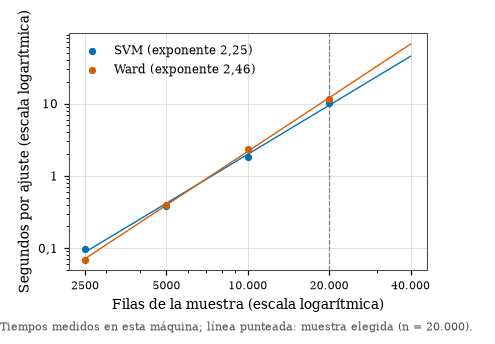

In [9]:
muestra = particion.muestra_estratificada(conjuntos, limpio[v.OBJETIVO_CLASIFICACION], TAMANO_MUESTRA)
huella_muestra = particion.huella(muestra.map({True: "1", False: "0"}))
ruta_particion = particion.escribir(conjuntos, muestra)
print(f"Muestra: {en_espanol(int(muestra.sum()))} filas de entrenamiento; huella {huella_muestra}")
print(f"Partición y muestra guardadas en {relativa(ruta_particion)} (ignorado por git)")
comprobar("La muestra sale solo de entrenamiento", conjuntos[muestra].eq(particion.ENTRENAMIENTO).all())
comprobar("La muestra conserva la proporción de no oficiales a menos de una décima de punto", abs(limpio.loc[muestra, v.OBJETIVO_CLASIFICACION].eq(v.CLASE_POSITIVA).mean() - y_clase_ent.eq(v.CLASE_POSITIVA).mean()) * 100 < 0.1)
cifra("huellaMuestra", huella_muestra)
cifra("huellaMuestraCorta", huella_muestra[:12])

figura, eje = plt.subplots(figsize=(4.2, 2.8))
rejilla = np.geomspace(TAMANOS_PRUEBA[0], 40_000, 50)
for (algoritmo, (a, b)), color in zip(leyes.items(), graficos.PALETA_CATEGORICA, strict=False):
    eje.scatter(tiempos.index, tiempos[f"{algoritmo} (s)"], color=color, s=14, label=f"{algoritmo} (exponente {en_espanol(b, 2)})", zorder=3)
    eje.plot(rejilla, a * rejilla**b, color=color, linewidth=0.9)
eje.axvline(TAMANO_MUESTRA, color=graficos.COLOR_APOYO, linestyle="--", linewidth=0.8)
eje.set(xscale="log", yscale="log", xlabel="Filas de la muestra (escala logarítmica)", ylabel="Segundos por ajuste (escala logarítmica)")
eje.set_xticks([*TAMANOS_PRUEBA, 40_000])
eje.xaxis.set_major_formatter(graficos.FORMATO_MILES)
eje.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
eje.yaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
eje.tick_params(axis="x", labelsize=7)
eje.legend(loc="upper left")
graficos.anotar_fuente(eje, f"Tiempos medidos en esta máquina; línea punteada: muestra elegida (n = {en_espanol(TAMANO_MUESTRA)}).")
figuras.guardar(figura, "muestra-tiempos")
plt.show()

**Lectura.** Los dos algoritmos crecen con un exponente cercano a 2, como se esperaba, y con costos muy parecidos en cada tamaño. La línea de cada uno es la ley de potencia ajustada, que también permite extrapolar: duplicar la muestra multiplica por más de cuatro el tiempo de cada ajuste, así que 40.000 filas ya no caben en el presupuesto. El tamaño elegido deja que la búsqueda de hiperparámetros de la fase 3 recorra cada configuración en alrededor de un minuto.

## 5. Mecanismo de los faltantes

La guía prohíbe imputar sin analizar antes por qué faltan los datos. Si los faltantes fueran completamente aleatorios (MCAR), no se relacionarían con nada: ni con el puntaje ni con las características del colegio. Si dependen de variables observadas (MAR), una imputación que use esas variables corrige el sesgo. Y si dependen del propio valor que falta (MNAR), ninguna imputación lo corrige del todo, aunque un indicador de faltante permite que el modelo lo aprenda. Todo se mide sobre el conjunto de entrenamiento.

La prueba de Little para MCAR no se usa: supone variables continuas con normalidad multivariada, y los faltantes de este análisis son categóricos. En su lugar, para cada variable con faltantes se compara el grupo con dato y el grupo sin dato de tres maneras:

- el puntaje global, con la t de Welch y la d de Cohen como tamaño del efecto;
- la naturaleza y la zona del colegio, con la χ² y la V de Cramér;
- una logística que predice el faltante con las características del colegio (naturaleza, zona, jornada, calendario, género y departamento), con el AUC como tamaño del efecto: 0,5 sería un faltante que el colegio no anticipa.

Con más de 370.000 filas, casi cualquier diferencia da un valor p diminuto, así que se interpreta el tamaño del efecto.

In [10]:
entrenamiento = limpio.loc[es_ent]
y_ent = entrenamiento[v.OBJETIVO_REGRESION]
OBSERVADAS_COLEGIO = ["COLE_NATURALEZA", "COLE_AREA_UBICACION", "COLE_JORNADA", "COLE_CALENDARIO", "COLE_GENERO", v.DEPARTAMENTO]
comprobar("Las variables del colegio que predicen el faltante están completas en entrenamiento", entrenamiento[OBSERVADAS_COLEGIO].notna().all().all())
diseno_colegio = pd.get_dummies(entrenamiento[OBSERVADAS_COLEGIO], drop_first=True, dtype=float)


def d_cohen(a: pd.Series, b: pd.Series) -> float:
    combinada = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return float((a.mean() - b.mean()) / combinada)


def v_cramer(tabla_contingencia: pd.DataFrame) -> tuple[float, float]:
    chi2, p, _, _ = stats.chi2_contingency(tabla_contingencia)
    return float(np.sqrt(chi2 / (tabla_contingencia.to_numpy().sum() * (min(tabla_contingencia.shape) - 1)))), float(p)


filas_mecanismo = []
for columna in [c for c in v.ENTRADA_REGRESION if entrenamiento[c].isna().sum() >= 30]:
    falta = entrenamiento[columna].isna()
    t = stats.ttest_ind(y_ent[falta], y_ent[~falta], equal_var=False)
    v_naturaleza, _ = v_cramer(pd.crosstab(falta, entrenamiento["COLE_NATURALEZA"]))
    v_zona, _ = v_cramer(pd.crosstab(falta, entrenamiento["COLE_AREA_UBICACION"]))
    logistica = LogisticRegression(max_iter=1000).fit(diseno_colegio, falta)
    auc = roc_auc_score(falta, logistica.predict_proba(diseno_colegio)[:, 1])
    filas_mecanismo.append({
        "variable": columna,
        "% faltante": porcentaje(falta.sum(), len(falta)),
        "Media sin dato": y_ent[falta].mean(),
        "Media con dato": y_ent[~falta].mean(),
        "d de Cohen": d_cohen(y_ent[falta], y_ent[~falta]),
        "p (Welch)": t.pvalue,
        "V naturaleza": v_naturaleza,
        "V zona": v_zona,
        "AUC colegio": auc,
    })
mecanismo = pd.DataFrame(filas_mecanismo).set_index("variable")
with pd.option_context("display.width", 200):
    tabla(mecanismo.drop(columns="p (Welch)"), 2)
print(f"\nMayor valor p de Welch: {mecanismo['p (Welch)'].max():.2e}")
for columna, fila in mecanismo.iterrows():
    sufijo = nombre_macro(columna)
    cifra(f"pctFalta{sufijo}", fila["% faltante"], 2)
    cifra(f"dFalta{sufijo}", fila["d de Cohen"], 2)
    cifra(f"aucFalta{sufijo}", fila["AUC colegio"], 2)
cifra("dFaltaMinimo", mecanismo["d de Cohen"].min(), 2)
cifra("dFaltaMaximo", mecanismo["d de Cohen"].max(), 2)
cifra("aucFaltaMaximo", mecanismo["AUC colegio"].max(), 2)
cifra("variablesConFaltantes", len(mecanismo))

[ok] Las variables del colegio que predicen el faltante están completas en entrenamiento


                     % faltante Media sin dato Media con dato d de Cohen V naturaleza V zona AUC colegio
variable                                                                                                
FAMI_ESTRATOVIVIENDA       6,74         230,61         251,55      -0,41         0,01   0,02        0,62
FAMI_EDUCACIONMADRE        5,84         229,94         251,39      -0,42         0,01   0,01        0,61
FAMI_EDUCACIONPADRE        5,81         230,18         251,37      -0,41         0,01   0,01        0,61
FAMI_TIENEINTERNET         5,95         229,59         251,44      -0,42         0,01   0,02        0,62
FAMI_TIENECOMPUTADOR       4,42         238,39         250,68      -0,24         0,00   0,00        0,60
FAMI_TIENEAUTOMOVIL        4,60         236,94         250,78      -0,27         0,00   0,00        0,60
FAMI_TIENELAVADORA         4,43         238,05         250,70      -0,24         0,00   0,00        0,60
FAMI_CUARTOSHOGAR          4,45         240,00         

'12'

### 5.1. Faltantes que se parecen al "No"

Para las variables del hogar, la comparación más elocuente es la del puntaje medio de quienes no respondieron frente al de cada respuesta. Si el grupo sin dato se parece a las respuestas de menor capacidad material, el faltante probablemente depende de la condición que no se declaró, que es el patrón de un mecanismo no aleatorio (MNAR). Además se mide cuánto coinciden los faltantes entre sí: si quien deja una pregunta en blanco deja las demás, los faltantes forman bloques.

In [11]:
HOGAR_CATEGORICO = [v.ESTRATO, v.EDUCACION_MADRE, "FAMI_TIENEINTERNET", "FAMI_TIENECOMPUTADOR"]
ETIQUETA_CORTA = {
    v.ESTRATO: "Estrato",
    v.EDUCACION_MADRE: "Educación madre",
    v.EDUCACION_PADRE: "Educación padre",
    "FAMI_TIENEINTERNET": "Internet",
    "FAMI_TIENECOMPUTADOR": "Computador",
    "FAMI_TIENEAUTOMOVIL": "Automóvil",
    "FAMI_TIENELAVADORA": "Lavadora",
    v.CUARTOS_HOGAR: "Cuartos",
    v.PERSONAS_HOGAR: "Personas",
    "COLE_CARACTER": "Carácter",
    "COLE_BILINGUE": "Bilingüe",
    v.EDAD: "Edad",
}
SIN_DATO = "Sin dato"
medias_por_respuesta = {
    columna: y_ent.groupby(entrenamiento[columna].fillna(SIN_DATO)).agg(["mean", "size"]) for columna in HOGAR_CATEGORICO
}
for columna, resumen in medias_por_respuesta.items():
    print(f"\n{ETIQUETA_CORTA[columna]}")
    tabla(resumen.rename(columns={"mean": "Puntaje medio", "size": "Estudiantes"}).sort_values("Puntaje medio"), 1)

internet = medias_por_respuesta["FAMI_TIENEINTERNET"]["mean"]
computador = medias_por_respuesta["FAMI_TIENECOMPUTADOR"]["mean"]
comprobar("Sin dato de internet, el puntaje medio está más cerca del No que del Sí", abs(internet[SIN_DATO] - internet["No"]) < abs(internet[SIN_DATO] - internet["Si"]))
comprobar("Sin dato de computador, el puntaje medio está más cerca del No que del Sí", abs(computador[SIN_DATO] - computador["No"]) < abs(computador[SIN_DATO] - computador["Si"]))
for columna, serie in (("Internet", internet), ("Computador", computador)):
    for respuesta, sufijo in (("Si", "Si"), ("No", "No"), (SIN_DATO, "SinDato")):
        cifra(f"media{columna}{sufijo}", serie[respuesta], 1)

COLUMNAS_FALTANTES = [c for c in mecanismo.index if c in ETIQUETA_CORTA]
coincidencia = entrenamiento[COLUMNAS_FALTANTES].isna().astype(float).corr()
bloque_a = [v.ESTRATO, v.EDUCACION_MADRE, v.EDUCACION_PADRE, "FAMI_TIENEINTERNET"]
bloque_b = ["FAMI_TIENECOMPUTADOR", "FAMI_TIENEAUTOMOVIL", "FAMI_TIENELAVADORA", v.CUARTOS_HOGAR, v.PERSONAS_HOGAR]


def rango_dentro(bloque: list[str]) -> tuple[float, float]:
    valores = coincidencia.loc[bloque, bloque].to_numpy()[np.triu_indices(len(bloque), 1)]
    return float(valores.min()), float(valores.max())


for nombre, bloque in (("A", bloque_a), ("B", bloque_b)):
    minimo, maximo = rango_dentro(bloque)
    print(f"Bloque {nombre} ({', '.join(ETIQUETA_CORTA[c] for c in bloque)}): correlación de los indicadores entre {en_espanol(minimo, 2)} y {en_espanol(maximo, 2)}")
    cifra(f"coincidenciaMinBloque{nombre}", minimo, 2)
    cifra(f"coincidenciaMaxBloque{nombre}", maximo, 2)
entre_bloques = coincidencia.loc[bloque_a, bloque_b].to_numpy()
print(f"Entre bloques: de {en_espanol(entre_bloques.min(), 2)} a {en_espanol(entre_bloques.max(), 2)}")
cifra("coincidenciaEntreBloquesMax", entre_bloques.max(), 2)


Estrato
                     Puntaje medio Estudiantes
FAMI_ESTRATOVIVIENDA                          
Sin Estrato                  212,5      13.843
Sin dato                     230,6      25.137
Estrato 1                    242,0     102.421
Estrato 6                    245,8        2692
Estrato 2                    253,7     125.981
Estrato 5                    261,4        5914
Estrato 3                    263,1      77.084
Estrato 4                    267,2      19.720

Educación madre
                                     Puntaje medio Estudiantes
FAMI_EDUCACIONMADRE                                           
Ninguno                                      211,3        7096
Primaria incompleta                          228,9      43.986
Sin dato                                     229,9      21.753
No Aplica                                    232,8         770
Primaria completa                            233,5      29.558
Secundaria (Bachillerato) incompleta         238,7      48.861


'0,45'

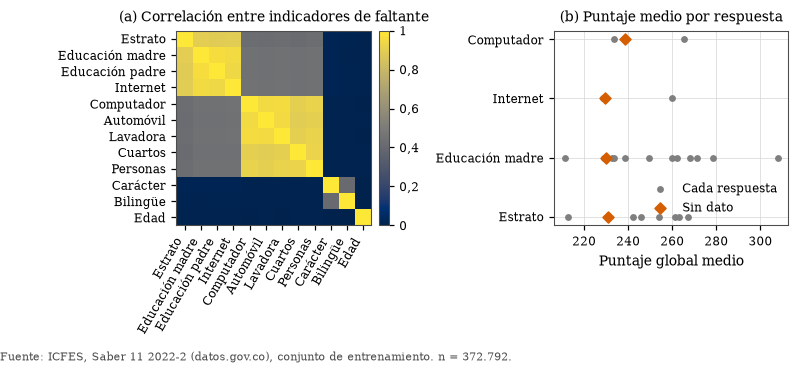

In [12]:
figura, (eje_a, eje_b) = plt.subplots(1, 2, figsize=(7.2, 3.2), gridspec_kw={"width_ratios": [1.05, 1]})
etiquetas = [ETIQUETA_CORTA[c] for c in coincidencia.columns]
imagen = eje_a.imshow(coincidencia.to_numpy(), cmap="cividis", vmin=0, vmax=1)
eje_a.set_xticks(range(len(etiquetas)), etiquetas, rotation=60, ha="right")
eje_a.set_yticks(range(len(etiquetas)), etiquetas)
eje_a.grid(False)
eje_a.set_title("(a) Correlación entre indicadores de faltante")
figura.colorbar(imagen, ax=eje_a, fraction=0.046, pad=0.03, format=graficos.FORMATO_DECIMAL)
posiciones = []
for i, columna in enumerate(HOGAR_CATEGORICO):
    resumen = medias_por_respuesta[columna]
    respuestas = [r for r in resumen.index if r != SIN_DATO]
    eje_b.scatter(resumen.loc[respuestas, "mean"], np.full(len(respuestas), i), color=graficos.COLOR_APOYO, s=12, zorder=2)
    eje_b.scatter(resumen.loc[SIN_DATO, "mean"], i, color=graficos.COLOR_NO_OFICIAL, marker="D", s=26, zorder=3)
    posiciones.append(ETIQUETA_CORTA[columna])
eje_b.scatter([], [], color=graficos.COLOR_APOYO, s=12, label="Cada respuesta")
eje_b.scatter([], [], color=graficos.COLOR_NO_OFICIAL, marker="D", s=26, label="Sin dato")
eje_b.set_yticks(range(len(posiciones)), posiciones)
eje_b.set_xlabel("Puntaje global medio")
eje_b.set_title("(b) Puntaje medio por respuesta")
eje_b.legend(loc="lower right")
figura.tight_layout()
graficos.anotar_fuente(eje_a, f"{FUENTE} n = {en_espanol(len(entrenamiento))}.")
figuras.guardar(figura, "faltantes-mecanismo")
plt.show()

**Lectura.** Ningún faltante es MCAR: en todas las variables del hogar, quienes no respondieron tienen un puntaje global medio distinto del de quienes sí respondieron, con tamaños de efecto que no son despreciables, y el colegio predice el faltante mejor que el azar. La figura agrega dos hechos. Primero, los faltantes del hogar forman dos bloques casi coincidentes (panel a): uno con el estrato, la educación de los padres y el internet, y otro con los bienes, los cuartos y las personas, lo que sugiere secciones del cuestionario que se dejaron completas en blanco. Segundo, en internet y computador, el grupo sin dato tiene un puntaje medio más cercano al de quienes respondieron "No" que al de quienes respondieron "Sí" (panel b). Ese es el patrón de un faltante que depende de la condición no declarada (MNAR), que no se puede probar con los datos observados pero sí tomar en cuenta: por eso cada imputación lleva un indicador de faltante, que deja al modelo aprender la diferencia del grupo sin dato en lugar de diluirla en la categoría imputada. Los faltantes del colegio (carácter y bilingüismo) siguen un patrón distinto, más ligado al tipo de colegio que al hogar, coherente con un mecanismo MAR que la imputación con las variables observadas puede corregir.

## 6. Imputación comparada en validación

Se comparan tres estrategias con la regresión múltiple en la especificación de componentes, ajustada en entrenamiento y medida en validación:

- **Eliminación por lista:** el modelo se ajusta solo con las filas completas y solo puede predecir las filas completas de validación, así que se reporta su cobertura.
- **Moda:** `SimpleImputer(strategy="most_frequent")` con un indicador de faltante por columna.
- **Iterativa:** `IterativeImputer` sobre las escalas ordinales (estrato, educación, bienes y bilingüismo) y las numéricas (cuartos, personas y edad), redondeada al valor posible más cercano, con moda para las nominales y el mismo indicador por columna. "Sin Estrato", "No sabe" y "No Aplica" son respuestas válidas fuera de la escala: no se imputan ni se reordenan.

Regla fijada antes de mirar el resultado: gana la de menor RMSE de validación entre las que cubren el 100 % de validación; si la diferencia es menor que 0,1 puntos, gana la más simple (la moda).

In [13]:
X_ent = limpio.loc[es_ent, list(v.ENTRADA_REGRESION)]
X_val = limpio.loc[es_val, list(v.ENTRADA_REGRESION)]
y_val = limpio.loc[es_val, v.OBJETIVO_REGRESION]
SIN_ATIPICOS = {v.EDAD: "conservar", v.HACINAMIENTO: "conservar"}

imputadores, segundos_imputacion = {}, {}
for estrategia in ("moda", "iterativa"):
    inicio = time.perf_counter()
    imputadores[estrategia] = v.Imputador(estrategia).fit(X_ent)
    segundos_imputacion[estrategia] = time.perf_counter() - inicio
imputados = {estrategia: (imputador.transform(X_ent), imputador.transform(X_val)) for estrategia, imputador in imputadores.items()}


def evaluar_validacion(estrategia: str, especificacion: str, atipicos: dict, departamento: str = "onehot") -> dict:
    """Ajusta la regresión múltiple sobre el entrenamiento ya imputado y la mide en validación."""
    X_e, X_v = imputados[estrategia]
    regresion = modelos.pipeline(v.PREDICTORES_REGRESION[especificacion], LinearRegression(), imputacion="lista", atipicos=atipicos, departamento=departamento)
    regresion.fit(X_e, y_ent)
    return modelos.metricas_regresion(y_val, regresion.predict(X_v))


completas_ent, completas_val = modelos.filas_completas(X_ent), modelos.filas_completas(X_val)
por_lista = modelos.pipeline(v.PREDICTORES_REGRESION["componentes"], LinearRegression(), imputacion="lista", atipicos=SIN_ATIPICOS)
por_lista.fit(X_ent[completas_ent], y_ent[completas_ent])
comparacion_imputacion = pd.DataFrame({
    "lista": {**modelos.metricas_regresion(y_val[completas_val], por_lista.predict(X_val[completas_val])), "cobertura": porcentaje(completas_val.sum(), len(X_val)), "segundos": 0.0},
    **{e: {**evaluar_validacion(e, "componentes", SIN_ATIPICOS), "cobertura": 100.0, "segundos": segundos_imputacion[e]} for e in ("moda", "iterativa")},
}).T
tabla(comparacion_imputacion, 3)

candidatas = comparacion_imputacion[comparacion_imputacion["cobertura"] == 100.0]
mejor = candidatas["rmse"].idxmin()
ganadora_imputacion = "moda" if candidatas.loc["moda", "rmse"] - candidatas.loc[mejor, "rmse"] < 0.1 else mejor
print(f"\nGanadora: {ganadora_imputacion}")
comprobar(f"modelos.IMPUTACION ({modelos.IMPUTACION}) es la ganadora en validación", modelos.IMPUTACION == ganadora_imputacion)
comprobar(f"IterativeImputer ajusta en menos de 5 minutos ({en_espanol(segundos_imputacion['iterativa'], 1)} s)", segundos_imputacion["iterativa"] < 300)
for estrategia, sufijo in (("lista", "Lista"), ("moda", "Moda"), ("iterativa", "Iterativa")):
    cifra(f"rmseImputacion{sufijo}", comparacion_imputacion.loc[estrategia, "rmse"], 3)
cifra("coberturaLista", comparacion_imputacion.loc["lista", "cobertura"], 1)
cifra("filasCompletasEntrenamiento", int(completas_ent.sum()))
cifra("medidaSegundosIterativa", segundos_imputacion["iterativa"], 1)
cifra("imputacionElegida", ganadora_imputacion)

             r2   rmse    mae cobertura segundos
lista     0,298 43,029 34,907    73,388        0
moda      0,314 42,972 34,844       100    1,093
iterativa 0,313 42,990 34,860       100   23,893

Ganadora: moda
[ok] modelos.IMPUTACION (moda) es la ganadora en validación
[ok] IterativeImputer ajusta en menos de 5 minutos (23,9 s)


'moda'

**Lectura.** La eliminación por lista no es una opción real para este problema: deja fuera a más de la cuarta parte de validación, justamente a los estudiantes que no respondieron alguna pregunta del hogar, que según §5 no son un subconjunto al azar, y el modelo no podría dar un pronóstico para ellos. Entre las dos imputaciones que cubren a todos, la iterativa no mejora a la moda, aunque tarda decenas de veces más: el indicador de faltante, presente en las dos, ya recoge la diferencia del grupo sin dato, y lo que la iterativa agrega al estimar mejor la categoría imputada no se traduce en un pronóstico más preciso.

## 7. Atípicos

Un valor extremo no es un error por serlo: puede ser legítimo y contener información (clase del 13 de octubre). Por eso la decisión se toma por variable:

- **Puntaje global:** se conserva. Está acotado entre 0 y 500 por construcción y es el objetivo; recortarlo cambiaría la pregunta.
- **Índice de bienes:** no tiene atípicos posibles (de 0 a 4).
- **Edad y hacinamiento:** tienen colas largas legítimas (estudiantes adultos, hogares de muchas personas en un cuarto). Se comparan tres tratamientos con el RMSE de validación: conservar, winsorizar en el percentil 99 del entrenamiento y transformar con logaritmo. La edad se evalúa en la especificación de componentes y el hacinamiento en la de derivadas, que es donde entra. Si la mejora frente a conservar es menor que 0,1 puntos, se conserva, porque conservar mantiene la escala natural de la variable y la interpretación de su coeficiente.

In [14]:
def atipicos_iqr(serie: pd.Series) -> tuple[int, float, float]:
    q1, q3 = serie.quantile([0.25, 0.75])
    bajo, alto = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return int(((serie < bajo) | (serie > alto)).sum()), float(bajo), float(alto)


hacinamiento_ent = entrenamiento[v.PERSONAS_HOGAR] / entrenamiento[v.CUARTOS_HOGAR]
resumen_atipicos = pd.DataFrame(
    {nombre: dict(zip(["Atípicos por IQR", "Límite inferior", "Límite superior"], atipicos_iqr(serie.dropna()), strict=True)) | {"Percentil 99": serie.quantile(0.99), "Máximo": serie.max()}
     for nombre, serie in (("Puntaje global", y_ent), ("Edad", entrenamiento[v.EDAD]), ("Hacinamiento", hacinamiento_ent))}
).T
tabla(resumen_atipicos, 2)
# El puntaje y la edad son enteros; el hacinamiento, una razón con dos decimales.
for nombre, sufijo, decimales in (("Puntaje global", "Global", 0), ("Edad", "Edad", 0), ("Hacinamiento", "Hacinamiento", 2)):
    cifra(f"atipicosIqr{sufijo}", resumen_atipicos.loc[nombre, "Atípicos por IQR"])
    cifra(f"percentilNoventaNueve{sufijo}", resumen_atipicos.loc[nombre, "Percentil 99"], decimales)
    cifra(f"maximo{sufijo}", resumen_atipicos.loc[nombre, "Máximo"], decimales)

TRATAMIENTOS = ("conservar", "winsorizar", "log")
comparacion_atipicos = pd.DataFrame({
    "Edad": {t: evaluar_validacion(modelos.IMPUTACION, "componentes", {**SIN_ATIPICOS, v.EDAD: t})["rmse"] for t in TRATAMIENTOS},
    "Hacinamiento": {t: evaluar_validacion(modelos.IMPUTACION, "derivadas", {**SIN_ATIPICOS, v.HACINAMIENTO: t})["rmse"] for t in TRATAMIENTOS},
})
print("\nRMSE de validación por tratamiento")
tabla(comparacion_atipicos, 3)
ganadores_atipicos = {}
for variable, columna in ((v.EDAD, "Edad"), (v.HACINAMIENTO, "Hacinamiento")):
    serie = comparacion_atipicos[columna]
    ganadores_atipicos[variable] = "conservar" if serie["conservar"] - serie.min() < 0.1 else serie.idxmin()
    for tratamiento in TRATAMIENTOS:
        cifra(f"rmseAtipicos{columna}{tratamiento.capitalize()}", serie[tratamiento], 3)
    cifra(f"tratamiento{columna}", ganadores_atipicos[variable])
print(f"Elegidos: {ganadores_atipicos}")
comprobar(f"modelos.ATIPICOS ({modelos.ATIPICOS}) coincide con lo elegido en validación", modelos.ATIPICOS == ganadores_atipicos)

               Atípicos por IQR Límite inferior Límite superior Percentil 99 Máximo
Puntaje global              483              93             405          370    477
Edad                     25.545           15,50           19,50           30     72
Hacinamiento             19.925            0,17            2,83         5,50      9



RMSE de validación por tratamiento
             Edad Hacinamiento
conservar  42,972       43,417
winsorizar 42,811       43,414
log        42,830       43,389
Elegidos: {'ESTU_EDAD': 'winsorizar', 'HACINAMIENTO': 'conservar'}
[ok] modelos.ATIPICOS ({'ESTU_EDAD': 'winsorizar', 'HACINAMIENTO': 'conservar'}) coincide con lo elegido en validación


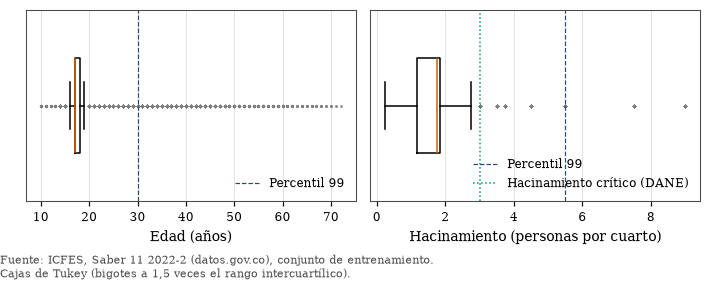

In [15]:
figura, ejes = plt.subplots(1, 2, figsize=(6.4, 2.4))
for eje, (nombre, serie, unidad) in zip(ejes, (("Edad", entrenamiento[v.EDAD].dropna(), "años"), ("Hacinamiento", hacinamiento_ent.dropna(), "personas por cuarto")), strict=True):
    eje.boxplot(serie, orientation="horizontal", widths=0.5, flierprops={"marker": ".", "markersize": 2, "markerfacecolor": graficos.COLOR_APOYO, "markeredgecolor": graficos.COLOR_APOYO, "alpha": 0.4}, medianprops={"color": graficos.COLOR_NO_OFICIAL})
    eje.axvline(serie.quantile(0.99), color=graficos.COLOR_PRINCIPAL, linestyle="--", linewidth=0.8, label="Percentil 99")
    eje.set(xlabel=f"{nombre} ({unidad})", yticks=[])
    eje.legend(loc="lower right")
ejes[1].axvline(3, color=graficos.PALETA_CATEGORICA[2], linestyle=":", linewidth=1, label="Hacinamiento crítico (DANE)")
ejes[1].legend(loc="lower right")
figura.tight_layout()
graficos.anotar_fuente(ejes[0], f"{FUENTE}\nCajas de Tukey (bigotes a 1,5 veces el rango intercuartílico).")
figuras.guardar(figura, "atipicos")
plt.show()

**Lectura.** La regla de Tukey marca como atípicos a miles de estudiantes porque la edad y el hacinamiento se concentran en pocos valores: casi todos tienen entre 16 y 18 años, y los rangos de personas y cuartos dan pocos cocientes posibles. Esos extremos son reales: adultos que validan el bachillerato y hogares hacinados, que son precisamente parte de lo que el modelo debe explicar. La comparación en validación decide si conviene acotarlos o cambiarles la escala; con la regla de 0,1 puntos, un tratamiento solo se adopta si mejora el pronóstico de forma apreciable.

## 8. Codificación, escalado y `Pipeline`

Todo lo que aprende algo de los datos vive dentro de un `Pipeline` de scikit-learn y se ajusta solo con el entrenamiento: la imputación, el tope de los atípicos, las categorías del one-hot, las medias y desviaciones del escalador y la codificación por objetivo. Así, validación y prueba solo se transforman, nunca se usan para ajustar (`tests/test_fuga.py` lo comprueba con valores centinela). Las decisiones de codificación son estas:

- **One-hot con referencias explícitas** para las categóricas: el nivel más bajo en las ordenadas (estrato 1, ninguna educación, sin el bien) y el más frecuente en las nominales, con Bogotá como referencia del departamento. Las mismas referencias se usan en statsmodels y en R, para que los coeficientes se puedan comparar uno a uno.
- **`StandardScaler`** sobre las numéricas (cuartos, personas, edad, índice de bienes y hacinamiento). En mínimos cuadrados no cambia las predicciones, pero sí es necesario para los modelos regularizados y de distancias de la fase 3.
- **Codificación por objetivo del departamento** (`TargetEncoder`) como variante para la fase 3: reemplaza los 33 departamentos por el puntaje medio suavizado de cada uno, calculado con validación cruzada interna para no usar el puntaje de la misma fila que codifica.

In [16]:
nominales = [c for c in v.REFERENCIAS if c not in v.REFERENCIAS_ORDENADAS and c in entrenamiento.columns and c != v.DEPARTAMENTO]
referencias = pd.DataFrame({
    "Referencia": {c: v.REFERENCIAS[c] for c in nominales},
    "Más frecuente en entrenamiento": {c: entrenamiento[c].mode().iloc[0] for c in nominales},
})
print(referencias.to_string())
comprobar("La referencia de cada nominal es su nivel más frecuente en entrenamiento", (referencias["Referencia"] == referencias["Más frecuente en entrenamiento"]).all())
comprobar("La referencia del departamento existe en entrenamiento", (entrenamiento[v.DEPARTAMENTO] == v.REFERENCIAS[v.DEPARTAMENTO]).any())

comparacion_departamento = pd.Series({
    variante: evaluar_validacion(modelos.IMPUTACION, "componentes", modelos.ATIPICOS, variante)["rmse"] for variante in ("onehot", "objetivo")
})
print("\nRMSE de validación según la codificación del departamento")
tabla(comparacion_departamento.to_frame("RMSE"), 3)
cifra("rmseDepartamentoOnehot", comparacion_departamento["onehot"], 3)
cifra("rmseDepartamentoObjetivo", comparacion_departamento["objetivo"], 3)

print("\n" + str(modelos.regresion_multiple("componentes")))
sin_imputar = modelos.pipeline(v.PREDICTORES_REGRESION["componentes"], LinearRegression(), imputacion="lista", atipicos=modelos.ATIPICOS)
columnas_codificadas = len(sin_imputar[:-1].fit(imputados[modelos.IMPUTACION][0], y_ent)["codificacion"].get_feature_names_out())
print(f"\nColumnas tras codificar (componentes, departamento en one-hot): {columnas_codificadas}")
cifra("columnasCodificadas", columnas_codificadas)

                    Referencia Más frecuente en entrenamiento
COLE_NATURALEZA        OFICIAL                        OFICIAL
COLE_AREA_UBICACION     URBANO                         URBANO
COLE_JORNADA            MAÑANA                         MAÑANA
COLE_CALENDARIO              A                              A
COLE_CARACTER        ACADÉMICO                      ACADÉMICO
COLE_BILINGUE                N                              N
COLE_GENERO              MIXTO                          MIXTO
ESTU_GENERO                  F                              F
[ok] La referencia de cada nominal es su nivel más frecuente en entrenamiento
[ok] La referencia del departamento existe en entrenamiento



RMSE de validación según la codificación del departamento
           RMSE
onehot   42,811
objetivo 42,998

Pipeline(steps=[('imputacion', Imputador()), ('derivadas', Derivadas()),
                ('atipicos',
                 Atipicos(tratamiento={'ESTU_EDAD': 'winsorizar',
                                       'HACINAMIENTO': 'conservar'})),
                ('seleccion',
                 Seleccion(predictores=('FAMI_ESTRATOVIVIENDA',
                                        'FAMI_EDUCACIONMADRE',
                                        'FAMI_EDUCACIONPADRE',
                                        'FAMI_TIENEINTERNET',
                                        'FAMI_TIENECOMPUTADOR',
                                        'FAMI_TIENEAUTOMOVIL',
                                        'FAMI_TIENELAVADORA',
                                        'F...
                                                   'FAMI_EDUCACIONMADRE',
                                                   'FAMI_EDUCA


Columnas tras codificar (componentes, departamento en one-hot): 95


'95'

**Lectura.** Con una sola columna para el departamento, la codificación por objetivo pierde menos de dos décimas de punto de RMSE frente al one-hot, que necesita 32. En la regresión de esta fase se conserva el one-hot, porque deja leer cuántos puntos separa a cada departamento de Bogotá; la variante por objetivo queda lista para los modelos de la fase 3, donde muchas columnas dispersas pesan más que la interpretación.

## 9. Laboratorio descriptivo: antes y después de preparar

La actividad 3 pide un laboratorio de estadística descriptiva con frecuencias, media, mediana, moda, varianza, desviación estándar y rango. Aquí se hace con un propósito concreto: mostrar qué le hace la preparación a las distribuciones del entrenamiento. "Antes" es el dato limpio, con sus faltantes; "después" es el dato que recibe el modelo, imputado y con el tratamiento de atípicos elegido. Las mismas cifras se calculan en R (§15) sobre el mismo archivo intermedio. La varianza y la desviación son muestrales, la moda es el valor más frecuente (el menor si hay empate) y el rango es el máximo menos el mínimo.

In [17]:
preparado = intermedios.entrenamiento_preparado(limpio, conjuntos)
comprobar("El entrenamiento preparado tiene todas las filas de entrenamiento", len(preparado) == int(es_ent.sum()))
comprobar("El entrenamiento preparado no tiene faltantes en lo que entra al modelo", preparado[[c for c in preparado.columns if not c.startswith(intermedios.PREFIJO_ANTES)]].notna().all().all())


def descriptivos(serie: pd.Series) -> dict[str, float]:
    serie = serie.dropna().astype("float64")
    return {
        "n": len(serie),
        "Media": serie.mean(),
        "Mediana": serie.median(),
        "Moda": serie.mode().min(),
        "Varianza": serie.var(),
        "Desviación": serie.std(),
        "Rango": serie.max() - serie.min(),
    }


NOMBRE_DESCRIPTIVA = {v.EDAD: "Edad", v.CUARTOS_HOGAR: "Cuartos", v.PERSONAS_HOGAR: "Personas", v.HACINAMIENTO: "Hacinamiento", v.OBJETIVO_REGRESION: "Puntaje global"}
filas_lab = []
for columna in intermedios.DESCRIPTIVAS_NUMERICAS:
    antes = preparado[f"{intermedios.PREFIJO_ANTES}{columna}"]
    despues = preparado[columna]
    filas_lab += [{"Variable": NOMBRE_DESCRIPTIVA[columna], "Momento": "Antes", **descriptivos(antes)}, {"Variable": NOMBRE_DESCRIPTIVA[columna], "Momento": "Después", **descriptivos(despues)}]
laboratorio = pd.DataFrame(filas_lab).set_index(["Variable", "Momento"])
tabla(laboratorio, 2)
for columna in intermedios.DESCRIPTIVAS_NUMERICAS:
    sufijo = nombre_macro(NOMBRE_DESCRIPTIVA[columna])
    for momento in ("Antes", "Después"):
        fila = laboratorio.loc[(NOMBRE_DESCRIPTIVA[columna], momento)]
        momento_macro = "Antes" if momento == "Antes" else "Despues"
        for estadistico, nombre in (("Media", "media"), ("Mediana", "mediana"), ("Moda", "moda"), ("Varianza", "varianza"), ("Desviación", "desviacion"), ("Rango", "rango")):
            cifra(f"lab{nombre.capitalize()}{sufijo}{momento_macro}", fila[estadistico], 2)
        cifra(f"labN{sufijo}{momento_macro}", fila["n"])


def frecuencias(antes: pd.Series, despues: pd.Series) -> pd.DataFrame:
    marco = pd.DataFrame({
        "Antes": antes.fillna(SIN_DATO).value_counts(),
        "Después": despues.value_counts(),
    }).fillna(0)
    marco["% antes"] = marco["Antes"] / marco["Antes"].sum() * 100
    marco["% después"] = marco["Después"] / marco["Después"].sum() * 100
    return marco


tablas_frecuencia = {
    columna: frecuencias(preparado[f"{intermedios.PREFIJO_ANTES}{columna}"], preparado[columna]) for columna in intermedios.DESCRIPTIVAS_CATEGORICAS
}
for columna, marco in tablas_frecuencia.items():
    print(f"\nFrecuencias de {ETIQUETA_CORTA[columna]}")
    tabla(marco, 1)
for columna, marco in tablas_frecuencia.items():
    sufijo = nombre_macro(ETIQUETA_CORTA[columna])
    cifra(f"labSinDato{sufijo}", marco.loc[SIN_DATO, "Antes"])
    cifra(f"labPctSinDato{sufijo}", marco.loc[SIN_DATO, "% antes"], 2)
cifra("labPctInternetSiAntes", tablas_frecuencia["FAMI_TIENEINTERNET"].loc["Si", "% antes"], 1)
cifra("labPctInternetSiDespues", tablas_frecuencia["FAMI_TIENEINTERNET"].loc["Si", "% después"], 1)

[ok] El entrenamiento preparado tiene todas las filas de entrenamiento
[ok] El entrenamiento preparado no tiene faltantes en lo que entra al modelo
                             n  Media Mediana Moda Varianza Desviación Rango
Variable       Momento                                                      
Edad           Antes   372.657  17,59      17   17     7,69       2,77    62
               Después 372.792  17,49      17   17     3,61       1,90    20
Cuartos        Antes   356.187   2,74       3    3     0,94       0,97     5
               Después 372.792   2,75       3    3     0,90       0,95     5
Personas       Antes   356.800   4,34    3,50 3,50     2,80       1,67  7,50
               Después 372.792   4,30    3,50 3,50     2,71       1,65  7,50
Hacinamiento   Antes   355.301   1,71    1,75 1,75     0,69       0,83  8,75
               Después 372.792   1,68    1,75 1,17     0,67       0,82  8,75
Puntaje global Antes   372.792 250,14     247  232  2686,58      51,83   449
     

'74,3'

Los gráficos del laboratorio se construyen con la interfaz de graficación de pandas, `DataFrame.plot`, que no dibuja por su cuenta: crea los objetos de Matplotlib (una `Figure` con sus `Axes`) y delega en ellos. Por eso cada panel se puede seguir ajustando con los métodos de Matplotlib, como se hace con los títulos de los ejes.

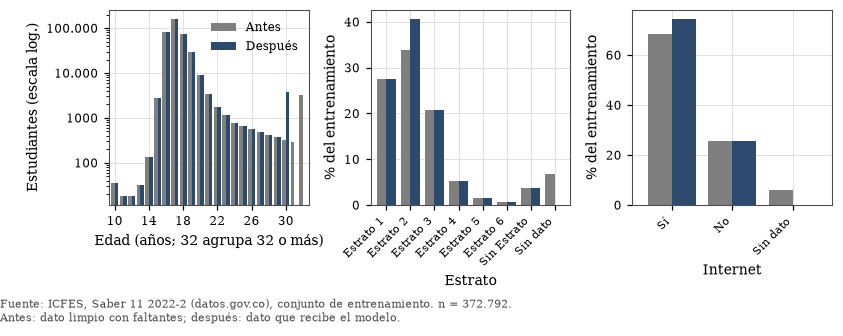

In [18]:
figura, ejes = plt.subplots(1, 3, figsize=(7.6, 2.8))
TOPE_GRAFICO_EDAD = 32
edades = pd.DataFrame({
    "Antes": preparado[f"{intermedios.PREFIJO_ANTES}{v.EDAD}"].clip(upper=TOPE_GRAFICO_EDAD).value_counts(),
    "Después": preparado[v.EDAD].clip(upper=TOPE_GRAFICO_EDAD).value_counts(),
}).fillna(0).sort_index()
edades.index = edades.index.astype(int)
edades.plot.bar(ax=ejes[0], width=0.85, color=[graficos.COLOR_APOYO, graficos.COLOR_PRINCIPAL], legend=True, logy=True)
ejes[0].set(xlabel=f"Edad (años; {TOPE_GRAFICO_EDAD} agrupa {TOPE_GRAFICO_EDAD} o más)", ylabel="Estudiantes (escala log.)")
ejes[0].yaxis.set_major_formatter(graficos.FORMATO_MILES)
ejes[0].set_xticks(range(0, len(edades), 4), [str(e) for e in edades.index[::4]], rotation=0)
for eje, columna in zip(ejes[1:], (v.ESTRATO, "FAMI_TIENEINTERNET"), strict=True):
    marco = tablas_frecuencia[columna][["% antes", "% después"]].rename(columns={"% antes": "Antes", "% después": "Después"})
    orden = [n for n in (*v.ESTRATOS, "Sin Estrato", "Si", "No", SIN_DATO) if n in marco.index]
    marco.loc[orden].plot.bar(ax=eje, width=0.8, color=[graficos.COLOR_APOYO, graficos.COLOR_PRINCIPAL], legend=False)
    eje.set(xlabel=ETIQUETA_CORTA[columna], ylabel="% del entrenamiento")
    eje.set_xticks(range(len(orden)), [{"Si": "Sí"}.get(n, n) for n in orden], rotation=45, ha="right", fontsize=7)
figura.tight_layout()
graficos.anotar_fuente(ejes[1], f"{FUENTE} n = {en_espanol(len(preparado))}.\nAntes: dato limpio con faltantes; después: dato que recibe el modelo.")
figuras.guardar(figura, "laboratorio-antes-despues")
plt.show()

**Lectura.** La imputación casi no mueve la tendencia central ni la dispersión de cuartos, personas y hacinamiento, porque los faltantes son pocos frente a más de 370.000 estudiantes. La winsorización de la edad sí se nota en la dispersión: la desviación estándar baja de 2,77 a 1,90 años y el rango de 62 a 20, mientras la media apenas pasa de 17,59 a 17,49; en el primer panel, los estudiantes mayores de 30 años se acumulan en 30. Lo que más cambia es la composición de las categorías del hogar. Con la moda, los estudiantes sin dato (alrededor del 6 % en cada variable) pasan en bloque a la respuesta más frecuente: todos los que no declararon su conexión quedan con internet, y la proporción con internet sube de 68 a 74 %, cuando §5 mostró que su puntaje se parece más al de quienes no lo tienen. Esa es la razón de los indicadores de faltante: le devuelven al modelo la información que la imputación borra.

## 10. Modelos base

Los modelos base fijan el umbral mínimo que cualquier modelo posterior tiene que superar para justificar su complejidad:

- **Regresión.** `DummyRegressor`, que predice siempre la media del entrenamiento, y una regresión lineal simple con la variable numérica de mayor correlación de Spearman (en valor absoluto) con el puntaje global en entrenamiento. Los candidatos son las cinco numéricas definidas para todo estudiante: cuartos, personas, edad, índice de bienes y hacinamiento.
- **Clasificación.** `DummyClassifier(strategy="prior")`, que asigna siempre la clase mayoritaria (oficial), y una regresión logística básica con las variables del hogar y del estudiante y `class_weight="balanced"`. La clase positiva es "NO OFICIAL", la minoritaria.

Todo se mide en entrenamiento y en validación: si un modelo rinde mucho mejor en entrenamiento que en validación, está sobreajustado.

In [19]:
y_val_clase = limpio.loc[es_val, v.OBJETIVO_CLASIFICACION]
X_ent_clase = limpio.loc[es_ent, list(v.ENTRADA_CLASIFICACION)]
X_val_clase = limpio.loc[es_val, list(v.ENTRADA_CLASIFICACION)]

spearman = pd.Series({c: stats.spearmanr(preparado[c], preparado[v.OBJETIVO_REGRESION]).statistic for c in v.NUMERICAS})
spearman = spearman.reindex(spearman.abs().sort_values(ascending=False).index)
tabla(spearman.to_frame("Spearman con el puntaje global"), 3)
predictor, rho = modelos.predictor_simple(preparado, preparado[v.OBJETIVO_REGRESION])
print(f"\nPredictor de la regresión lineal simple: {predictor} (rho de Spearman = {en_espanol(rho, 3)})")
comprobar("El predictor simple es el de mayor |Spearman| en entrenamiento", predictor == spearman.index[0])
NOMBRE_NUMERICA = {v.CUARTOS_HOGAR: "cuartos del hogar", v.PERSONAS_HOGAR: "personas del hogar", v.EDAD: "edad", v.INDICE_BIENES: "índice de bienes", v.HACINAMIENTO: "hacinamiento"}
cifra("predictorSimple", NOMBRE_NUMERICA[predictor])
cifra("spearmanSimple", rho, 3)

modelos_regresion = {
    "dummyRegresion": modelos.dummy_regresion().fit(X_ent, y_ent),
    "linealSimple": modelos.lineal_simple(predictor).fit(X_ent, y_ent),
}
modelos_clasificacion = {
    "dummyClasificacion": modelos.dummy_clasificacion().fit(X_ent_clase, y_clase_ent),
    "logisticaBase": modelos.logistica_base().fit(X_ent_clase, y_clase_ent),
}


def metricas_de_regresion(modelo, X: pd.DataFrame, y: pd.Series) -> dict[str, float]:
    return modelos.metricas_regresion(y, modelo.predict(X))


def metricas_de_clasificacion(modelo, X: pd.DataFrame, y: pd.Series) -> dict[str, float]:
    probabilidad = modelo.predict_proba(X)[:, list(modelo.classes_).index(v.CLASE_POSITIVA)]
    return modelos.metricas_clasificacion(y, modelo.predict(X), probabilidad)


def resumen_regresion(nombres: dict) -> pd.DataFrame:
    filas = {(nombre, conjunto): metricas_de_regresion(modelo, X, y) for nombre, modelo in nombres.items() for conjunto, X, y in (("entrenamiento", X_ent, y_ent), ("validación", X_val, y_val))}
    return pd.DataFrame(filas).T


resultados_base_regresion = resumen_regresion(modelos_regresion)
tabla(resultados_base_regresion, 3)
resultados_base_clasificacion = pd.DataFrame({
    (nombre, conjunto): metricas_de_clasificacion(modelo, X, y)
    for nombre, modelo in modelos_clasificacion.items()
    for conjunto, X, y in (("entrenamiento", X_ent_clase, y_clase_ent), ("validación", X_val_clase, y_val_clase))
}).T
print()
tabla(resultados_base_clasificacion, 3)

SUFIJO_MODELO = {"dummyRegresion": "Dummy", "linealSimple": "Simple", "regresionMultiple": "Multiple", "dummyClasificacion": "DummyClase", "logisticaBase": "Logistica"}
SUFIJO_CONJUNTO = {"entrenamiento": "Entrenamiento", "validación": "Validacion", "prueba": "Prueba"}


MACRO_METRICA = {"r2": "rCuadrado", "f1": "fUno"}


def registrar_metricas(resultados: pd.DataFrame) -> None:
    for (nombre, conjunto), fila in resultados.iterrows():
        for metrica, valor in fila.items():
            decimales = 1 if metrica in {"rmse", "mae"} else 3
            cifra(f"{MACRO_METRICA.get(metrica, metrica)}{SUFIJO_CONJUNTO[conjunto]}{SUFIJO_MODELO[nombre]}", valor, decimales)


registrar_metricas(resultados_base_regresion)
registrar_metricas(resultados_base_clasificacion)
comprobar("La lineal simple supera al Dummy en RMSE de validación", resultados_base_regresion.loc[("linealSimple", "validación"), "rmse"] < resultados_base_regresion.loc[("dummyRegresion", "validación"), "rmse"])
comprobar("La logística supera al Dummy en AUC de validación", resultados_base_clasificacion.loc[("logisticaBase", "validación"), "auc"] > resultados_base_clasificacion.loc[("dummyClasificacion", "validación"), "auc"])

                   Spearman con el puntaje global
INDICE_BIENES                               0,328
ESTU_EDAD                                  -0,308
FAMI_PERSONASHOGAR                         -0,102
HACINAMIENTO                               -0,092
FAMI_CUARTOSHOGAR                           0,003



Predictor de la regresión lineal simple: INDICE_BIENES (rho de Spearman = 0,328)
[ok] El predictor simple es el de mayor |Spearman| en entrenamiento


                                 r2   rmse    mae
dummyRegresion entrenamiento      0 51,832 42,949
               validación    -0,000 51,868 42,940
linealSimple   entrenamiento  0,106 49,018 40,240
               validación     0,105 49,060 40,229



                                 accuracy precision recall    f1   auc
dummyClasificacion entrenamiento    0,774         0      0     0 0,500
                   validación       0,774         0      0     0 0,500
logisticaBase      entrenamiento    0,712     0,414  0,663 0,510 0,766
                   validación       0,707     0,409  0,660 0,505 0,762
[ok] La lineal simple supera al Dummy en RMSE de validación
[ok] La logística supera al Dummy en AUC de validación


**Lectura.** El índice de bienes es el predictor numérico con más asociación con el puntaje, seguido de cerca por la edad, con signo negativo (la extraedad). La lineal simple con ese índice explica cerca de la décima parte de la varianza y baja el RMSE en unos tres puntos frente al `DummyRegressor`, que por construcción no explica nada. Entrenamiento y validación casi coinciden en los dos: un modelo con uno o ningún predictor no tiene con qué sobreajustarse. En clasificación, el `DummyClassifier` acierta en el 77 % de los casos sin aprender nada, porque siempre dice "oficial"; su F1 y su exhaustividad son cero, y por eso la exactitud no sirve para comparar en esta tarea. La logística con pesos de clase sacrifica exactitud para encontrar dos de cada tres estudiantes de colegios no oficiales, con un AUC cercano a 0,76: el hogar separa bastante, pero lejos de por completo, los dos tipos de colegio. Estas métricas de validación son los umbrales que la fase 3 debe superar.

## 11. Regresión simple y múltiple

### 11.1. Especificación de la múltiple

El índice de bienes es la suma exacta de los cuatro bienes, así que la regresión no puede usar los dos a la vez: la matriz de diseño sería singular. Por eso hay dos especificaciones. La de **componentes** usa cada variable del hogar por separado; la de **derivadas** reemplaza los bienes, la educación de cada padre, los cuartos y las personas por el índice de bienes, la máxima educación y el hacinamiento. Las dos comparten el estrato, el colegio, el estudiante y los indicadores de faltante.

La colinealidad se mide con el VIF generalizado de Fox y Monette por variable (GVIF), que es lo que calcula `car::vif` en R. El VIF clásico por columna no sirve aquí: en una variable categórica con una referencia poco frecuente, como "Ninguno" en la educación, los dummies de los demás niveles casi suman uno y su VIF se infla sin que haya colinealidad entre variables, y lo mismo pasa con los indicadores de faltante, que se mueven juntos por construcción (§5). El GVIF agrupa las columnas de cada variable, y los indicadores van como un solo bloque. Su versión ajustada, GVIF^(1/(2gl)), se compara con la raíz de 10, el equivalente del umbral de 10 del VIF clásico. Gana la especificación que cumple el umbral en todas sus variables con el menor RMSE de validación.

In [20]:
UMBRAL_GVIF = np.sqrt(10)
gvif_por_especificacion, filas_especificacion = {}, []
for especificacion in ("componentes", "derivadas"):
    sin_imputar = modelos.pipeline(v.PREDICTORES_REGRESION[especificacion], LinearRegression(), imputacion="lista", atipicos=modelos.ATIPICOS)
    X_codificado = sin_imputar[:-1].fit_transform(imputados[modelos.IMPUTACION][0], y_ent)
    gvif = modelos.vif_generalizado(X_codificado, v.PREDICTORES_REGRESION[especificacion])
    vif_columna = pd.Series(np.diag(np.linalg.inv(np.corrcoef(X_codificado.to_numpy(dtype=float), rowvar=False))), index=X_codificado.columns)
    gvif_por_especificacion[especificacion] = gvif
    filas_especificacion.append({
        "especificación": especificacion,
        "columnas": X_codificado.shape[1],
        "VIF máximo por columna": vif_columna.max(),
        "columnas con VIF > 10": int((vif_columna > 10).sum()),
        "GVIF ajustado máximo": gvif["gvif_ajustado"].max(),
        "RMSE de validación": evaluar_validacion(modelos.IMPUTACION, especificacion, modelos.ATIPICOS)["rmse"],
    })
comparacion_especificacion = pd.DataFrame(filas_especificacion).set_index("especificación")
tabla(comparacion_especificacion, 3)
elegibles = comparacion_especificacion[comparacion_especificacion["GVIF ajustado máximo"] < UMBRAL_GVIF]
ganadora_especificacion = elegibles["RMSE de validación"].idxmin()
print(f"\nGanadora: {ganadora_especificacion}")
print(f"\nGVIF por variable de la especificación {ganadora_especificacion}")
tabla(gvif_por_especificacion[ganadora_especificacion], 2)
comprobar(f"modelos.ESPECIFICACION ({modelos.ESPECIFICACION}) es la ganadora en validación", modelos.ESPECIFICACION == ganadora_especificacion)
for especificacion, fila in comparacion_especificacion.iterrows():
    sufijo = especificacion.capitalize()
    cifra(f"columnas{sufijo}", fila["columnas"])
    cifra(f"vifMaximoColumna{sufijo}", fila["VIF máximo por columna"], 1)
    cifra(f"columnasVifAlto{sufijo}", fila["columnas con VIF > 10"])
    cifra(f"gvifAjustadoMaximo{sufijo}", fila["GVIF ajustado máximo"], 2)
    cifra(f"rmseEspecificacion{sufijo}", fila["RMSE de validación"], 3)
cifra("especificacionElegida", ganadora_especificacion)
cifra("umbralGvif", UMBRAL_GVIF, 2)

               columnas VIF máximo por columna columnas con VIF > 10 GVIF ajustado máximo RMSE de validación
especificación                                                                                              
componentes          95                 18,168                     7                1,367             42,811
derivadas            79                 25,859                    10                1,361             43,250

Ganadora: componentes

GVIF por variable de la especificación componentes
                        gl gvif gvif_ajustado
variable                                     
COLE_NATURALEZA          1 1,87          1,37
FAMI_TIENECOMPUTADOR     1 1,61          1,27
FAMI_TIENEINTERNET       1 1,53          1,24
FAMI_CUARTOSHOGAR        1 1,41          1,19
ESTU_EDAD                1 1,39          1,18
FAMI_PERSONASHOGAR       1 1,39          1,18
FAMI_TIENEAUTOMOVIL      1 1,30          1,14
COLE_AREA_UBICACION      1 1,30          1,14
FAMI_TIENELAVADORA       1 1,

'3,16'

### 11.2. statsmodels: simple y múltiple

statsmodels ajusta por mínimos cuadrados ordinarios sobre el entrenamiento ya preparado (imputado, con las derivadas y el tratamiento de atípicos, sin escalar), el mismo archivo intermedio que lee R. La fórmula declara las referencias de cada categórica con `C(variable, Treatment(referencia))`, así que cada coeficiente se lee como la diferencia en puntos frente a la referencia, con las demás variables constantes.

In [21]:
predictores_finales = v.PREDICTORES_REGRESION[modelos.ESPECIFICACION]
indicadores_finales = [c for c in preparado.columns if v.es_indicador(c)]
formula_multiple = modelos.formula(v.OBJETIVO_REGRESION, predictores_finales, indicadores_finales)
simple_sm = smf.ols(f"{v.OBJETIVO_REGRESION} ~ {predictor}", preparado).fit()
multiple_sm = smf.ols(formula_multiple, preparado).fit()
print(simple_sm.summary(slim=True))

DIGITOS = {"0": "Cero", "1": "Uno", "2": "Dos", "3": "Tres", "4": "Cuatro", "5": "Cinco", "6": "Seis", "7": "Siete", "8": "Ocho", "9": "Nueve"}


def macro_termino(clave: str) -> str:
    """Nombre de macro de un término (`VARIABLE=nivel`): solo letras, con los dígitos en palabras."""
    ascii_ = unicodedata.normalize("NFKD", clave).encode("ascii", "ignore").decode()
    ascii_ = "".join(f" {DIGITOS[c]} " if c.isdigit() else c for c in ascii_)
    return "".join(p.capitalize() for p in re.findall(r"[A-Za-z]+", ascii_.lower()))


coeficientes = pd.DataFrame({
    "coeficiente": multiple_sm.params,
    "ic_inferior": multiple_sm.conf_int()[0],
    "ic_superior": multiple_sm.conf_int()[1],
    "p": multiple_sm.pvalues,
})
coeficientes.index = [modelos.clave_termino(n) for n in coeficientes.index]
print(f"\nRegresión múltiple ({modelos.ESPECIFICACION}): R² = {en_espanol(multiple_sm.rsquared, 3)}, R² ajustado = {en_espanol(multiple_sm.rsquared_adj, 3)}, {len(coeficientes) - 1} coeficientes además del intercepto")
with pd.option_context("display.max_rows", 200):
    tabla(coeficientes.drop(columns="p").round(2), 2)
print(f"\nCoeficientes con p mayor que 0,05: {int((coeficientes['p'] > 0.05).sum())}")
comprobar("Ningún término de la múltiple es un puntaje", not any(t.startswith("PUNT_") for t in coeficientes.index))

cifra("rCuadradoSimpleEntrenamiento", simple_sm.rsquared, 3)
cifra("pendienteSimple", simple_sm.params[predictor], 2)
cifra("pendienteSimpleInf", simple_sm.conf_int().loc[predictor, 0], 2)
cifra("pendienteSimpleSup", simple_sm.conf_int().loc[predictor, 1], 2)
cifra("interceptoSimple", simple_sm.params["Intercept"], 2)
cifra("rCuadradoMultipleEntrenamiento", multiple_sm.rsquared, 3)
cifra("rCuadradoAjustadoMultiple", multiple_sm.rsquared_adj, 3)
cifra("coeficientesMultiple", len(coeficientes) - 1)
cifra("coeficientesNoSignificativos", int((coeficientes["p"] > 0.05).sum()))
for clave, fila in coeficientes.iterrows():
    nombre = "Intercepto" if clave == "Intercept" else macro_termino(clave)
    cifra(f"coef{nombre}", fila["coeficiente"], 1)
    cifra(f"coefInf{nombre}", fila["ic_inferior"], 1)
    cifra(f"coefSup{nombre}", fila["ic_superior"], 1)

                            OLS Regression Results                            
Dep. Variable:            PUNT_GLOBAL   R-squared:                       0.106
Model:                            OLS   Adj. R-squared:                  0.106
No. Observations:              372792   F-statistic:                 4.404e+04
Covariance Type:            nonrobust   Prob (F-statistic):               0.00
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept       218.2164      0.172   1268.695      0.000     217.879     218.554
INDICE_BIENES    13.7367      0.065    209.858      0.000      13.608      13.865

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.

Regresión múltiple (componentes): R² = 0,318, R² ajustado = 0,318, 95 coeficientes además del intercepto
                                                         coeficiente ic

### 11.3. scikit-learn: el mismo modelo dentro del `Pipeline`

El `Pipeline` de scikit-learn ajusta el mismo modelo desde el dato limpio, con la imputación, las derivadas, los atípicos, la codificación y el escalado como pasos. El escalado cambia los coeficientes de las numéricas (quedan en puntos por desviación estándar), pero no las predicciones de mínimos cuadrados. Se comprueba con las predicciones de validación y devolviendo los coeficientes a la escala original.

In [22]:
regresion = modelos.regresion_multiple().fit(X_ent, y_ent)
modelos_regresion["regresionMultiple"] = regresion
validacion_preparada = modelos.preparacion().fit(X_ent).transform(X_val)
diferencia_prediccion = float(np.abs(regresion.predict(X_val) - multiple_sm.predict(validacion_preparada).to_numpy()).max())

codificacion = regresion["codificacion"]
escalador = codificacion.named_transformers_["numericas"]
coeficientes_sklearn = pd.Series(regresion["modelo"].coef_, index=codificacion.get_feature_names_out())
desescalar = pd.Series(escalador.scale_, index=escalador.feature_names_in_)
coeficientes_sklearn[desescalar.index] = coeficientes_sklearn[desescalar.index] / desescalar
intercepto_sklearn = regresion["modelo"].intercept_ - float((coeficientes_sklearn[desescalar.index] * pd.Series(escalador.mean_, index=desescalar.index)).sum())
coeficientes_sklearn.index = [modelos.clave_termino(n) for n in coeficientes_sklearn.index]
coeficientes_sm = coeficientes["coeficiente"].drop("Intercept")
comprobar("statsmodels y scikit-learn estiman los mismos términos", set(coeficientes_sklearn.index) == set(coeficientes_sm.index))
diferencia_coeficientes = float((coeficientes_sklearn - coeficientes_sm.reindex(coeficientes_sklearn.index)).abs().max())
diferencia_intercepto = abs(intercepto_sklearn - coeficientes.loc["Intercept", "coeficiente"])
print(f"Mayor diferencia de predicción en validación: {diferencia_prediccion:.2e} puntos")
print(f"Mayor diferencia de coeficientes en la escala original: {diferencia_coeficientes:.2e} puntos; intercepto: {diferencia_intercepto:.2e}")
comprobar("statsmodels y scikit-learn predicen lo mismo en validación (diferencia menor que 1e-6 puntos)", diferencia_prediccion < 1e-6)
comprobar("statsmodels y scikit-learn dan los mismos coeficientes en la escala original (diferencia menor que 1e-6)", max(diferencia_coeficientes, diferencia_intercepto) < 1e-6)
cifra("diferenciaPrediccionSklearn", f"{diferencia_prediccion:.1e}".replace(".", ","))
cifra("diferenciaCoeficientesSklearn", f"{diferencia_coeficientes:.1e}".replace(".", ","))

resultados_multiple = resumen_regresion({"regresionMultiple": regresion})
tabla(resultados_multiple, 3)
registrar_metricas(resultados_multiple)

[ok] statsmodels y scikit-learn estiman los mismos términos
Mayor diferencia de predicción en validación: 7.45e-12 puntos
Mayor diferencia de coeficientes en la escala original: 6.79e-12 puntos; intercepto: 6.25e-13
[ok] statsmodels y scikit-learn predicen lo mismo en validación (diferencia menor que 1e-6 puntos)
[ok] statsmodels y scikit-learn dan los mismos coeficientes en la escala original (diferencia menor que 1e-6)


                                   r2   rmse    mae
regresionMultiple entrenamiento 0,318 42,803 34,716
                  validación    0,319 42,811 34,708


## 12. Supuestos, influencia y robustez

Los coeficientes de mínimos cuadrados son insesgados si el modelo está bien especificado, pero sus errores estándar e intervalos dependen de cuatro supuestos. Cada uno se revisa con una prueba o un gráfico, y para los que fallan se usa una corrección en lugar de ignorarlos:

- **Linealidad:** residuos frente a valores ajustados, que deberían rodear el cero sin curvatura.
- **Independencia:** los estudiantes de un mismo departamento comparten contexto, así que sus errores pueden estar correlacionados. El orden de las filas no tiene sentido temporal, por eso no se usa la prueba de Durbin y Watson; se comparan los errores estándar clásicos con los agrupados por departamento.
- **Normalidad de los residuos:** gráfico cuantil-cuantil con 1.000 cuantiles, asimetría y curtosis. Con más de 370.000 filas, el teorema central del límite sostiene la inferencia sobre los coeficientes aunque los residuos no sean normales.
- **Homocedasticidad:** prueba de Breusch y Pagan y gráfico de escala y ubicación. Si falla, los errores HC3 de MacKinnon y White corrigen los intervalos.

La influencia se revisa con la distancia de Cook y el umbral de 4/n: se reajusta el modelo sin esos casos y se comparan los coeficientes, como pidió el docente. Como contraste robusto se ajusta una regresión de Huber, que da menos peso a los residuos grandes. Ningún gráfico muestra estudiantes individuales: los residuos se dibujan agrupados en celdas hexagonales de 10 o más estudiantes y la distancia de Cook como distribución.

In [23]:
residuos = multiple_sm.resid
ajustados = multiple_sm.fittedvalues
influencia = multiple_sm.get_influence()
residuos_estandarizados = influencia.resid_studentized_internal
distancia_cook = influencia.cooks_distance[0]
filas_entrenamiento = len(residuos)
umbral_cook = 4 / filas_entrenamiento
influyentes = distancia_cook > umbral_cook

breusch_pagan = sms.het_breuschpagan(residuos, multiple_sm.model.exog)
asimetria_residuos = float(stats.skew(residuos))
curtosis_residuos = float(stats.kurtosis(residuos))
print(f"Breusch y Pagan: LM = {en_espanol(breusch_pagan[0], 1)}, p = {breusch_pagan[1]:.2e}")
print(f"Residuos: asimetría {en_espanol(asimetria_residuos, 3)} y curtosis en exceso {en_espanol(curtosis_residuos, 3)}")
print(f"Casos con distancia de Cook mayor que 4/n ({umbral_cook:.2e}): {en_espanol(int(influyentes.sum()))} ({en_espanol(porcentaje(influyentes.sum(), filas_entrenamiento), 2)} %)")
comprobar("La influencia no tiene puntos de palanca 1 (ningún término depende de un solo estudiante)", np.isfinite(residuos_estandarizados).all())
cifra("breuschPaganLm", breusch_pagan[0], 0)
cifra("asimetriaResiduos", asimetria_residuos, 2)
cifra("curtosisResiduos", curtosis_residuos, 2)
cifra("casosCook", int(influyentes.sum()))
cifra("pctCasosCook", porcentaje(influyentes.sum(), filas_entrenamiento), 2)
cifra("maximoCook", float(distancia_cook.max()), 4)

Breusch y Pagan: LM = 7549,2, p = 0.00e+00
Residuos: asimetría 0,152 y curtosis en exceso -0,243
Casos con distancia de Cook mayor que 4/n (1.07e-05): 16.233 (4,35 %)
[ok] La influencia no tiene puntos de palanca 1 (ningún término depende de un solo estudiante)


'0,0009'

El panel de diagnóstico se construye con la interfaz orientada a objetos de Matplotlib: una `Figure` con cuatro `Axes`, y en cada uno los objetos que lo dibujan (`Artist`): la colección hexagonal, las líneas y los textos. §16 vuelve sobre esa jerarquía.

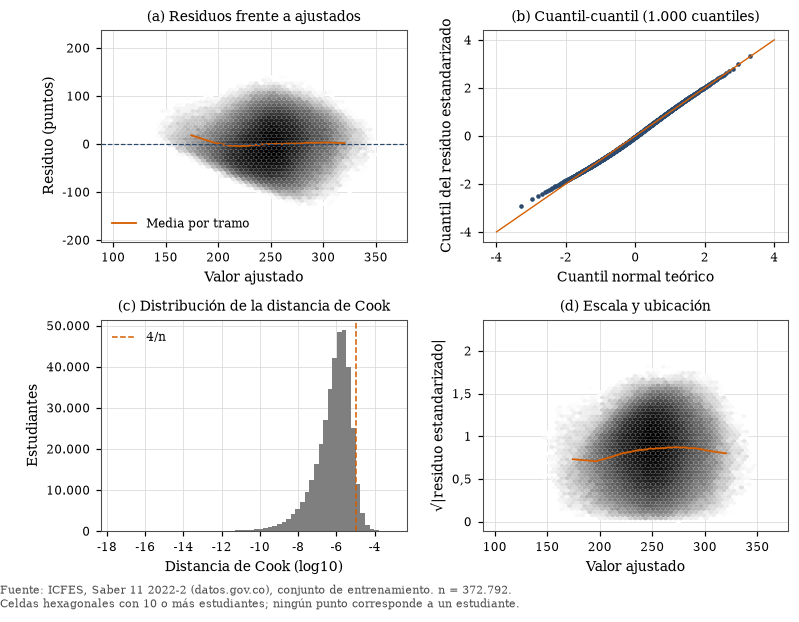

In [24]:
figura_diagnostico = plt.figure(figsize=(7.2, 5.4))
ejes_diagnostico = figura_diagnostico.subplots(2, 2)
eje_residuos, eje_qq, eje_cook, eje_escala = ejes_diagnostico.ravel()


def media_por_tramos(x: np.ndarray, y: np.ndarray, tramos: int = 40) -> tuple[np.ndarray, np.ndarray]:
    cortes = np.quantile(x, np.linspace(0, 1, tramos + 1))
    grupo = np.clip(np.searchsorted(cortes, x, side="right") - 1, 0, tramos - 1)
    centros = pd.Series(x).groupby(grupo).mean().to_numpy()
    medias = pd.Series(y).groupby(grupo).mean().to_numpy()
    return centros, medias


panal = eje_residuos.hexbin(ajustados, residuos, gridsize=55, mincnt=10, cmap="Greys", bins="log", linewidths=0)
eje_residuos.plot(*media_por_tramos(ajustados.to_numpy(), residuos.to_numpy()), color=graficos.COLOR_NO_OFICIAL, linewidth=1.2, label="Media por tramo")
eje_residuos.axhline(0, color=graficos.COLOR_PRINCIPAL, linewidth=0.8, linestyle="--")
eje_residuos.set(xlabel="Valor ajustado", ylabel="Residuo (puntos)", title="(a) Residuos frente a ajustados")
eje_residuos.legend(loc="lower left")

probabilidades = (np.arange(1, 1001) - 0.5) / 1000
teoricos = stats.norm.ppf(probabilidades)
empiricos = np.quantile(residuos_estandarizados, probabilidades)
eje_qq.scatter(teoricos, empiricos, s=4, color=graficos.COLOR_PRINCIPAL)
eje_qq.plot([-4, 4], [-4, 4], color=graficos.COLOR_NO_OFICIAL, linewidth=0.9)
eje_qq.set(xlabel="Cuantil normal teórico", ylabel="Cuantil del residuo estandarizado", title="(b) Cuantil-cuantil (1.000 cuantiles)")

eje_cook.hist(np.log10(distancia_cook[distancia_cook > 0]), bins=60, color=graficos.COLOR_APOYO)
eje_cook.axvline(np.log10(umbral_cook), color=graficos.COLOR_NO_OFICIAL, linestyle="--", linewidth=1, label="4/n")
eje_cook.set(xlabel="Distancia de Cook (log10)", ylabel="Estudiantes", title="(c) Distribución de la distancia de Cook")
eje_cook.yaxis.set_major_formatter(graficos.FORMATO_MILES)
eje_cook.legend(loc="upper left")

raiz_absoluta = np.sqrt(np.abs(residuos_estandarizados))
eje_escala.hexbin(ajustados, raiz_absoluta, gridsize=55, mincnt=10, cmap="Greys", bins="log", linewidths=0)
eje_escala.plot(*media_por_tramos(ajustados.to_numpy(), raiz_absoluta), color=graficos.COLOR_NO_OFICIAL, linewidth=1.2)
eje_escala.set(xlabel="Valor ajustado", ylabel="√|residuo estandarizado|", title="(d) Escala y ubicación")
for eje in ejes_diagnostico.ravel():
    eje.xaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
    eje.yaxis.set_major_formatter(graficos.FORMATO_MILES if eje is eje_cook else graficos.FORMATO_DECIMAL)
figura_diagnostico.tight_layout()
graficos.anotar_fuente(eje_cook, f"{FUENTE} n = {en_espanol(filas_entrenamiento)}.\nCeldas hexagonales con 10 o más estudiantes; ningún punto corresponde a un estudiante.")
figuras.guardar(figura_diagnostico, "diagnostico-regresion")
plt.show()

In [25]:
sin_influyentes = smf.ols(formula_multiple, preparado.loc[~influyentes]).fit()
cambio = pd.DataFrame({"con todos": multiple_sm.params, "sin influyentes": sin_influyentes.params.reindex(multiple_sm.params.index)})
cambio.index = [modelos.clave_termino(n) for n in cambio.index]
cambio["diferencia"] = cambio["sin influyentes"] - cambio["con todos"]
terminos_perdidos = int(cambio["sin influyentes"].isna().sum())
correlacion_coeficientes = float(cambio.drop(index="Intercept").dropna()[["con todos", "sin influyentes"]].corr().iloc[0, 1])
TERMINOS_CLAVE = [t for t in (
    "FAMI_TIENEINTERNET=Si",
    "FAMI_TIENECOMPUTADOR=Si",
    "FAMI_ESTRATOVIVIENDA=Estrato 6",
    "COLE_NATURALEZA=NO OFICIAL",
    "COLE_AREA_UBICACION=RURAL",
    f"{v.INDICE_BIENES}",
    f"{v.EDUCACION_MAXIMA}=Postgrado",
    "FAMI_EDUCACIONMADRE=Postgrado",
    "FALTA_FAMI_TIENEINTERNET",
    v.EDAD,
) if t in cambio.index]
print(f"R² sin los casos influyentes: {en_espanol(sin_influyentes.rsquared, 3)} (con todos: {en_espanol(multiple_sm.rsquared, 3)})")
print(f"Correlación entre los coeficientes con y sin esos casos: {en_espanol(correlacion_coeficientes, 4)}; términos que desaparecen: {terminos_perdidos}")
tabla(cambio.loc[TERMINOS_CLAVE], 2)
cifra("rCuadradoSinInfluyentes", sin_influyentes.rsquared, 3)
cifra("correlacionCoefSinInfluyentes", correlacion_coeficientes, 3)

R² sin los casos influyentes: 0,362 (con todos: 0,318)
Correlación entre los coeficientes con y sin esos casos: 0,9975; términos que desaparecen: 0
                               con todos sin influyentes diferencia
FAMI_TIENEINTERNET=Si               7,02            7,27       0,25
FAMI_TIENECOMPUTADOR=Si             9,01            9,22       0,21
FAMI_ESTRATOVIVIENDA=Estrato 6    -15,37          -17,72      -2,35
COLE_NATURALEZA=NO OFICIAL         12,45           12,10      -0,35
COLE_AREA_UBICACION=RURAL         -10,26          -10,07       0,18
FAMI_EDUCACIONMADRE=Postgrado      34,25           37,66       3,41
FALTA_FAMI_TIENEINTERNET           -4,29           -3,75       0,54
ESTU_EDAD                          -3,68           -3,93      -0,25


'0,998'

In [26]:
huber = modelos.pipeline(predictores_finales, HuberRegressor(alpha=0, max_iter=1000)).fit(X_ent, y_ent)
coeficientes_huber = pd.Series(huber["modelo"].coef_, index=huber["codificacion"].get_feature_names_out())
escala_huber = huber["codificacion"].named_transformers_["numericas"]
desescalar_huber = pd.Series(escala_huber.scale_, index=escala_huber.feature_names_in_)
coeficientes_huber[desescalar_huber.index] = coeficientes_huber[desescalar_huber.index] / desescalar_huber
coeficientes_huber.index = [modelos.clave_termino(n) for n in coeficientes_huber.index]
huber_validacion = metricas_de_regresion(huber, X_val, y_val)
contraste = pd.DataFrame({"MCO": coeficientes_sm.reindex(TERMINOS_CLAVE), "Huber": coeficientes_huber.reindex(TERMINOS_CLAVE)})
tabla(contraste, 2)
print(f"\nValidación: Huber RMSE {en_espanol(huber_validacion['rmse'], 3)} y MAE {en_espanol(huber_validacion['mae'], 3)}; MCO RMSE {en_espanol(resultados_multiple.loc[('regresionMultiple', 'validación'), 'rmse'], 3)} y MAE {en_espanol(resultados_multiple.loc[('regresionMultiple', 'validación'), 'mae'], 3)}")
correlacion_huber = float(np.corrcoef(coeficientes_sm.reindex(coeficientes_huber.index), coeficientes_huber)[0, 1])
print(f"Correlación entre los coeficientes de MCO y de Huber: {en_espanol(correlacion_huber, 4)}")
cifra("rmseValidacionHuber", huber_validacion["rmse"], 1)
cifra("maeValidacionHuber", huber_validacion["mae"], 1)
cifra("correlacionCoefHuber", correlacion_huber, 3)
for termino in TERMINOS_CLAVE:
    cifra(f"huber{macro_termino(termino)}", coeficientes_huber[termino], 1)

                                  MCO  Huber
FAMI_TIENEINTERNET=Si            7,02   7,25
FAMI_TIENECOMPUTADOR=Si          9,01   9,32
FAMI_ESTRATOVIVIENDA=Estrato 6 -15,37 -17,19
COLE_NATURALEZA=NO OFICIAL      12,45  13,00
COLE_AREA_UBICACION=RURAL      -10,26 -10,42
FAMI_EDUCACIONMADRE=Postgrado   34,25  36,51
FALTA_FAMI_TIENEINTERNET        -4,29  -4,85
ESTU_EDAD                       -3,68  -3,60

Validación: Huber RMSE 42,853 y MAE 34,644; MCO RMSE 42,811 y MAE 34,708
Correlación entre los coeficientes de MCO y de Huber: 0,9992


In [27]:
grupos_departamento = pd.factorize(preparado[v.DEPARTAMENTO])[0]
errores = pd.DataFrame({
    "clásico": multiple_sm.bse,
    "HC3": pd.Series(multiple_sm.get_robustcov_results(cov_type="HC3").bse, index=multiple_sm.params.index),
    "agrupado por departamento": pd.Series(multiple_sm.get_robustcov_results(cov_type="cluster", groups=grupos_departamento).bse, index=multiple_sm.params.index),
})
errores.index = [modelos.clave_termino(n) for n in errores.index]
errores["HC3 / clásico"] = errores["HC3"] / errores["clásico"]
errores["agrupado / clásico"] = errores["agrupado por departamento"] / errores["clásico"]
tabla(errores.loc[TERMINOS_CLAVE], 2)
print(f"\nMediana de la razón agrupado / clásico en todos los términos: {en_espanol(errores['agrupado / clásico'].median(), 2)}")
agrupado_ic = pd.DataFrame({
    "inferior": coeficientes_sm.reindex(TERMINOS_CLAVE) - 1.96 * errores.loc[TERMINOS_CLAVE, "agrupado por departamento"],
    "superior": coeficientes_sm.reindex(TERMINOS_CLAVE) + 1.96 * errores.loc[TERMINOS_CLAVE, "agrupado por departamento"],
})
cifra("razonHcTresMediana", errores["HC3 / clásico"].median(), 2)
cifra("razonAgrupadoMediana", errores["agrupado / clásico"].median(), 2)
TERMINOS_REVISADOS = list(dict.fromkeys([*TERMINOS_CLAVE, *intermedios.TERMINOS_FIGURA]))
razones_revisadas = errores.loc[TERMINOS_REVISADOS, "agrupado / clásico"]
print(f"Mayor razón agrupado / clásico en los términos clave y en los de la figura de coeficientes: {en_espanol(razones_revisadas.max(), 1)} ({razones_revisadas.idxmax()})")
cifra("razonAgrupadoMaxima", razones_revisadas.max(), 1)
for termino in TERMINOS_CLAVE:
    cifra(f"agrupadoInf{macro_termino(termino)}", agrupado_ic.loc[termino, "inferior"], 1)
    cifra(f"agrupadoSup{macro_termino(termino)}", agrupado_ic.loc[termino, "superior"], 1)

                               clásico  HC3 agrupado por departamento HC3 / clásico agrupado / clásico
FAMI_TIENEINTERNET=Si             0,20 0,19                      0,56          0,97               2,81
FAMI_TIENECOMPUTADOR=Si           0,18 0,18                      0,37          1,01               2,05
FAMI_ESTRATOVIVIENDA=Estrato 6    0,84 0,90                      3,86          1,07               4,57
COLE_NATURALEZA=NO OFICIAL        0,23 0,24                      1,71          1,06               7,48
COLE_AREA_UBICACION=RURAL         0,21 0,21                      1,70          0,97               7,99
FAMI_EDUCACIONMADRE=Postgrado     0,78 0,79                      0,99          1,01               1,26
FALTA_FAMI_TIENEINTERNET          1,00 0,99                      1,14          0,99               1,14
ESTU_EDAD                         0,04 0,04                      0,23          0,99               5,35

Mediana de la razón agrupado / clásico en todos los términos: 1,74
Mayor

La figura pone lado a lado los dos intervalos de los 14 términos que discute el informe: el clásico, que supone errores independientes, y el agrupado por departamento. Así se ve, y no solo se calcula, cuánta precisión le quita al modelo la falta de independencia.

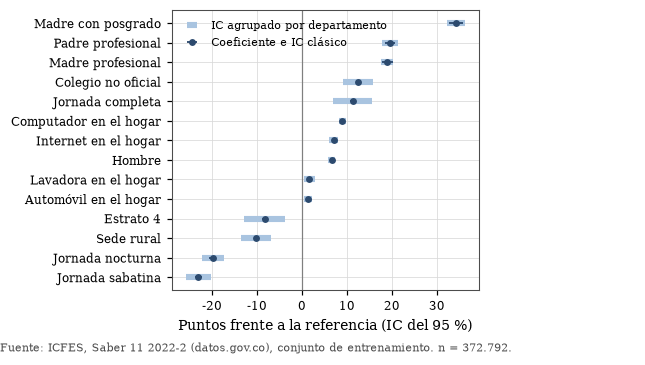

[ok] Ningún IC agrupado de los términos de la figura de coeficientes cruza el cero


In [28]:
terminos_figura = list(intermedios.TERMINOS_FIGURA)
comparacion_ic = pd.DataFrame({
    "etiqueta": [intermedios.TERMINOS_FIGURA[t] for t in terminos_figura],
    "coeficiente": coeficientes_sm.reindex(terminos_figura).to_numpy(),
    "error_clasico": errores.loc[terminos_figura, "clásico"].to_numpy(),
    "error_agrupado": errores.loc[terminos_figura, "agrupado por departamento"].to_numpy(),
}).sort_values("coeficiente")
posiciones = np.arange(len(comparacion_ic))
figura_ic, eje_ic = plt.subplots(figsize=(3.6, 3.3))
eje_ic.axvline(0, color=graficos.COLOR_APOYO, linewidth=0.8)
eje_ic.errorbar(comparacion_ic["coeficiente"], posiciones, xerr=1.96 * comparacion_ic["error_agrupado"], fmt="none", ecolor="#A9C4E0", elinewidth=4, label="IC agrupado por departamento")
eje_ic.errorbar(comparacion_ic["coeficiente"], posiciones, xerr=1.96 * comparacion_ic["error_clasico"], fmt="o", markersize=3.5, color=graficos.COLOR_PRINCIPAL, elinewidth=1.2, label="Coeficiente e IC clásico")
eje_ic.set_yticks(posiciones, comparacion_ic["etiqueta"])
eje_ic.set_xlabel("Puntos frente a la referencia (IC del 95 %)")
eje_ic.xaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
eje_ic.legend(loc="upper left", fontsize=7)
graficos.anotar_fuente(eje_ic, f"{FUENTE} n = {en_espanol(filas_entrenamiento)}.")
figuras.guardar(figura_ic, "coeficientes-ic-agrupado")
plt.show()
limite_inferior = comparacion_ic["coeficiente"] - 1.96 * comparacion_ic["error_agrupado"]
limite_superior = comparacion_ic["coeficiente"] + 1.96 * comparacion_ic["error_agrupado"]
comprobar("Ningún IC agrupado de los términos de la figura de coeficientes cruza el cero", bool((limite_inferior * limite_superior > 0).all()))

**Lectura.** Los cuatro paneles y las pruebas dicen lo mismo: el modelo es razonable y sus coeficientes son estables, pero sus errores estándar clásicos son demasiado optimistas.

- **Linealidad (panel a).** Los residuos rodean el cero en casi todo el rango; solo en los valores ajustados más bajos, donde hay pocos estudiantes, la media por tramo sube: el modelo subestima un poco a quienes predice peor. La forma de rombo viene de que el puntaje está acotado.
- **Normalidad (panel b).** Los cuantiles siguen la diagonal, con la cola inferior algo más liviana que la normal (asimetría y curtosis en exceso cercanas a cero). Con este tamaño de muestra, eso no afecta la inferencia sobre los coeficientes.
- **Influencia (panel c).** Cerca del 4 % de los estudiantes supera el umbral de 4/n, pero ninguno domina: la distancia de Cook máxima es diminuta. Al reajustar sin ellos, el R² sube (se quitaron justamente los peor ajustados) y los coeficientes casi no cambian: su correlación con los originales es superior a 0,99, y los términos clave se mueven menos de cuatro puntos.
- **Homocedasticidad (panel d).** La dispersión crece hacia el centro de los valores ajustados y la prueba de Breusch y Pagan la rechaza, pero los errores HC3 casi no cambian frente a los clásicos (razón cercana a 1): la heterocedasticidad es real y leve.
- **Independencia.** Es el supuesto que más pesa, y no lo muestra el panel sino la comparación de errores estándar y la figura de los dos intervalos. Los errores agrupados por departamento son, en la mediana, 1,7 veces los clásicos, y hasta unas ocho veces en las características del colegio (naturaleza, zona y jornada), que se agrupan en el territorio. Aun así, ningún intervalo de los términos clave ni de los de la figura cruza el cero, así que ninguna conclusión cambia de signo; el informe usa la figura de los dos intervalos para los coeficientes.
- **Robustez.** La regresión de Huber da coeficientes casi idénticos (correlación superior a 0,99), con un RMSE de validación apenas mayor y un MAE apenas menor, lo esperado de una pérdida que castiga menos los residuos grandes. Los atípicos del puntaje no están moviendo el modelo.

## 13. Interpretación

Dos preguntas guían la lectura del modelo. La primera es cuántos puntos se asocian con cada condición del hogar y del colegio cuando las demás se mantienen constantes, que son los coeficientes con su intervalo. La segunda es qué parte de la varianza explica cada bloque de variables: el R² por bloques (el que logra cada bloque solo y lo que pierde el modelo sin él) y el f² de Cohen de cada bloque, f² = (R² completo − R² sin el bloque) / (1 − R² completo), que la literatura lee como pequeño desde 0,02, mediano desde 0,15 y grande desde 0,35. Un coeficiente con p diminuto puede ser irrelevante en la práctica: significativo no quiere decir importante.

In [29]:
nombres_diseno = [modelos.clave_termino(n) for n in multiple_sm.model.exog_names]
diseno = multiple_sm.model.exog
y_diseno = multiple_sm.model.endog
BLOQUE_DE = {**{c: "Hogar" for c in (*v.HOGAR, *v.DERIVADAS)}, **{c: "Colegio" for c in v.COLEGIO}, **{c: "Estudiante" for c in v.ESTUDIANTE}}


def bloque(termino: str) -> str:
    if termino == "Intercept":
        return "Intercepto"
    variable = termino.split("=")[0].removeprefix(v.PREFIJO_FALTA)
    return BLOQUE_DE[variable]


bloques = pd.Series([bloque(t) for t in nombres_diseno])


def r_cuadrado(columnas: np.ndarray) -> float:
    beta, *_ = np.linalg.lstsq(diseno[:, columnas], y_diseno, rcond=None)
    residuo = y_diseno - diseno[:, columnas] @ beta
    return float(1 - residuo @ residuo / ((y_diseno - y_diseno.mean()) @ (y_diseno - y_diseno.mean())))


r2_completo = r_cuadrado(np.arange(diseno.shape[1]))
filas_bloques = []
for nombre_bloque in ("Hogar", "Colegio", "Estudiante"):
    solo = np.flatnonzero(bloques.isin(["Intercepto", nombre_bloque]))
    sin = np.flatnonzero(~bloques.eq(nombre_bloque))
    r2_sin = r_cuadrado(sin)
    filas_bloques.append({"bloque": nombre_bloque, "columnas": int(bloques.eq(nombre_bloque).sum()), "R² solo": r_cuadrado(solo), "R² sin el bloque": r2_sin, "R² que aporta": r2_completo - r2_sin, "f²": (r2_completo - r2_sin) / (1 - r2_completo)})
por_bloques = pd.DataFrame(filas_bloques).set_index("bloque")
tabla(por_bloques, 3)
comprobar("El R² por bloques reproduce el R² de statsmodels", abs(r2_completo - multiple_sm.rsquared) < 1e-9)
for nombre_bloque, fila in por_bloques.iterrows():
    cifra(f"rCuadradoSolo{nombre_bloque}", fila["R² solo"], 3)
    cifra(f"rCuadradoAporta{nombre_bloque}", fila["R² que aporta"], 3)
    cifra(f"fCuadrado{nombre_bloque}", fila["f²"], 3)

INTERPRETAR = [t for t in coeficientes.index if t != "Intercept" and not v.es_indicador(t) and not t.startswith(v.DEPARTAMENTO)]
print()
tabla(coeficientes.loc[INTERPRETAR, ["coeficiente", "ic_inferior", "ic_superior"]].sort_values("coeficiente"), 1)
departamentos = coeficientes.loc[[t for t in coeficientes.index if t.startswith(f"{v.DEPARTAMENTO}=")], "coeficiente"]
print(f"\nDepartamentos frente a Bogotá: de {en_espanol(departamentos.min(), 1)} ({departamentos.idxmin().split('=')[1]}) a {en_espanol(departamentos.max(), 1)} ({departamentos.idxmax().split('=')[1]}) puntos")
cifra("departamentoMinimo", departamentos.min(), 1)
cifra("departamentoMinimoNombre", departamentos.idxmin().split("=")[1].title())
cifra("departamentoMaximo", departamentos.max(), 1)
cifra("departamentoMaximoNombre", departamentos.idxmax().split("=")[1].title())

           columnas R² solo R² sin el bloque R² que aporta    f²
bloque                                                          
Hogar            43   0,211            0,247         0,071 0,104
Colegio          49   0,219            0,247         0,071 0,104
Estudiante        3   0,084            0,301         0,017 0,024
[ok] El R² por bloques reproduce el R² de statsmodels

                                                         coeficiente ic_inferior ic_superior
COLE_JORNADA=SABATINA                                          -23,1       -23,8       -22,3
COLE_JORNADA=NOCHE                                             -19,8       -20,6       -19,1
FAMI_ESTRATOVIVIENDA=Sin Estrato                               -16,4       -17,2       -15,6
FAMI_ESTRATOVIVIENDA=Estrato 6                                 -15,4       -17,0       -13,7
COLE_AREA_UBICACION=RURAL                                      -10,3       -10,7        -9,8
FAMI_ESTRATOVIVIENDA=Estrato 5                                

'Santander'

**Lectura.** El hogar y el colegio aportan, cada uno por su lado, casi la misma parte de la varianza que no comparten (alrededor de siete puntos de R², con un f² cercano a 0,10, un efecto entre pequeño y mediano), y cada bloque por sí solo explica alrededor de la quinta parte. La mayor parte de lo que explican es compartida: los hogares de mayor capacidad material se concentran en ciertos colegios, y el modelo no puede atribuir esa parte a uno u otro bloque. La edad aporta poco por su cuenta, aunque su coeficiente es claro: cada año de más se asocia con unos cuatro puntos menos, con lo demás constante.

En puntos, con todo lo demás constante: tener computador o internet en el hogar se asocia con entre 7 y 9 puntos más cada uno, la educación de los padres marca las diferencias más grandes (un posgrado de la madre frente a ninguna educación supera los 30 puntos), estudiar en un colegio no oficial suma alrededor de 12 y la zona rural resta alrededor de 10. Las jornadas nocturna y sabatina, que atienden sobre todo a adultos, restan 20 puntos o más. El estrato, en cambio, tiene coeficientes negativos crecientes cuando ya están en el modelo los bienes, la educación de los padres y el colegio: no significa que vivir en estrato alto baje el puntaje, sino que, entre estudiantes con el mismo hogar declarado y el mismo tipo de colegio, el estrato ya no agrega ventaja: la asociación bruta que describió la fase 1 pasa por esas otras variables. Son asociaciones, no efectos causales: el modelo no dice qué pasaría si un hogar recibiera internet, sino cómo se diferencian los puntajes de hogares que ya lo tienen.

## 14. Evaluación única en prueba

Con todas las decisiones tomadas en validación, cada modelo se evalúa una sola vez en el conjunto de prueba. `modelos.evaluar_en_prueba` registra cada evaluación en `resultados/evaluaciones-prueba.json` y falla si un modelo se evalúa dos veces; ninguna celda anterior lee ese registro.

In [30]:
X_pru = limpio.loc[es_pru, list(v.ENTRADA_REGRESION)]
y_pru = limpio.loc[es_pru, v.OBJETIVO_REGRESION]
X_pru_clase = limpio.loc[es_pru, list(v.ENTRADA_CLASIFICACION)]
y_pru_clase = limpio.loc[es_pru, v.OBJETIVO_CLASIFICACION]
filas_prueba = {}
for nombre, modelo in modelos_regresion.items():
    filas_prueba[(nombre, "prueba")] = metricas_de_regresion(modelo, X_pru, y_pru)
    modelos.evaluar_en_prueba(RUTA_PRUEBA, nombre, filas_prueba[(nombre, "prueba")])
for nombre, modelo in modelos_clasificacion.items():
    filas_prueba[(nombre, "prueba")] = metricas_de_clasificacion(modelo, X_pru_clase, y_pru_clase)
    modelos.evaluar_en_prueba(RUTA_PRUEBA, nombre, filas_prueba[(nombre, "prueba")])
prueba = pd.DataFrame(filas_prueba).T
regresion_tres = pd.concat([resultados_base_regresion, resultados_multiple, prueba.loc[list(modelos_regresion), ["r2", "rmse", "mae"]]]).sort_index()
clasificacion_tres = pd.concat([resultados_base_clasificacion, prueba.loc[list(modelos_clasificacion), resultados_base_clasificacion.columns]]).sort_index()
tabla(regresion_tres, 3)
print()
tabla(clasificacion_tres, 3)
registrar_metricas(prueba.loc[list(modelos_regresion), ["r2", "rmse", "mae"]])
registrar_metricas(prueba.loc[list(modelos_clasificacion), resultados_base_clasificacion.columns])
evaluados = [fila["modelo"] for fila in json.loads(RUTA_PRUEBA.read_text(encoding="utf-8"))]
comprobar("La prueba se usó una sola vez por modelo, en los cinco modelos", len(evaluados) == len(set(evaluados)) == 5)
brecha = regresion_tres.loc[("regresionMultiple", "entrenamiento"), "rmse"] - regresion_tres.loc[("regresionMultiple", "prueba"), "rmse"]
cifra("brechaRmseMultiple", abs(brecha), 2)

                                    r2   rmse    mae
dummyRegresion    entrenamiento      0 51,832 42,949
                  prueba        -0,000 51,828 43,022
                  validación    -0,000 51,868 42,940
linealSimple      entrenamiento  0,106 49,018 40,240
                  prueba         0,106 48,991 40,303
                  validación     0,105 49,060 40,229
regresionMultiple entrenamiento  0,318 42,803 34,716
                  prueba         0,319 42,783 34,755
                  validación     0,319 42,811 34,708

                                 accuracy precision recall    f1   auc
dummyClasificacion entrenamiento    0,774         0      0     0 0,500
                   prueba           0,774         0      0     0 0,500
                   validación       0,774         0      0     0 0,500
logisticaBase      entrenamiento    0,712     0,414  0,663 0,510 0,766
                   prueba           0,712     0,414  0,666 0,511 0,765
                   validación       0,707  

'0,02'

**Lectura.** Las métricas de prueba quedan prácticamente iguales a las de validación en los cinco modelos, y las de entrenamiento también: ningún modelo base ni la regresión múltiple está sobreajustado, lo que se espera de modelos lineales con más de 370.000 filas y menos de un centenar de coeficientes. La regresión múltiple explica cerca del 32 % de la varianza del puntaje global en estudiantes que no vio, con un error típico de unos 43 puntos sobre una escala de 0 a 500, frente a 52 del modelo que siempre predice la media. Esa es la respuesta de esta fase a S1, y es el umbral que los modelos regularizados y los ensambles de la fase 3 tienen que superar.

## 15. Paridad con R

`src/r/fase-2.R` ajusta con `lm` la simple y la múltiple sobre el mismo entrenamiento preparado (el archivo intermedio que escribe `saber11.intermedios`), con las mismas referencias, y calcula el laboratorio descriptivo con las mismas definiciones. Aquí se comparan sus resultados con los de statsmodels y pandas: coeficientes por término con una diferencia absoluta menor que 1e-6 puntos, R² y descriptivos con una diferencia relativa menor que 1e-6 y frecuencias idénticas.

In [31]:
RUTA_R = RUTA_RESULTADOS / "r" / "fase-2.json"
comprobar(f"Existe la salida del script de R ({relativa(RUTA_R)})", RUTA_R.is_file())
salida_r = json.loads(RUTA_R.read_text(encoding="utf-8"))
print(f"R {salida_r['version_r']} y ggplot2 {salida_r['version_ggplot2']}")


def diferencia_relativa(a: float, b: float) -> float:
    return abs(a - b) / max(abs(a), abs(b), 1e-12)


def coeficientes_r(modelo: str) -> pd.Series:
    return pd.Series({clave: valores["estimado"] for clave, valores in salida_r[modelo]["coeficientes"].items()})


python_simple = pd.Series({modelos.clave_termino(n): c for n, c in simple_sm.params.items()})
python_multiple = coeficientes["coeficiente"]
filas_paridad = []
for nombre, python, r in (("simple", python_simple, coeficientes_r("simple")), ("múltiple", python_multiple, coeficientes_r("multiple"))):
    comprobar(f"Paridad con R: la regresión {nombre} tiene los mismos términos ({len(r)})", set(python.index) == set(r.index))
    diferencia = float((python - r.reindex(python.index)).abs().max())
    filas_paridad.append({"comparación": f"Coeficientes de la {nombre}", "valores": len(r), "mayor diferencia": diferencia, "tipo": "absoluta (puntos)"})
    comprobar(f"Paridad con R: coeficientes de la regresión {nombre} (diferencia absoluta máxima {diferencia:.1e})", diferencia < 1e-6)
for nombre, modelo_sm, clave in (("simple", simple_sm, "simple"), ("múltiple", multiple_sm, "multiple")):
    diferencia = diferencia_relativa(modelo_sm.rsquared, salida_r[clave]["r2"])
    filas_paridad.append({"comparación": f"R² de la {nombre}", "valores": 1, "mayor diferencia": diferencia, "tipo": "relativa"})
    comprobar(f"Paridad con R: R² de la regresión {nombre}", diferencia < 1e-6)

ESTADISTICO_R = {"n": "n", "Media": "media", "Mediana": "mediana", "Moda": "moda", "Varianza": "varianza", "Desviación": "desviacion", "Rango": "rango"}
diferencias_lab = []
for columna in intermedios.DESCRIPTIVAS_NUMERICAS:
    for momento, clave_r in (("Antes", "antes"), ("Después", "despues")):
        fila = laboratorio.loc[(NOMBRE_DESCRIPTIVA[columna], momento)]
        for estadistico, nombre_r in ESTADISTICO_R.items():
            diferencias_lab.append(diferencia_relativa(fila[estadistico], salida_r["laboratorio"]["numericas"][columna][clave_r][nombre_r]))
filas_paridad.append({"comparación": "Descriptivos antes y después", "valores": len(diferencias_lab), "mayor diferencia": max(diferencias_lab), "tipo": "relativa"})
comprobar(f"Paridad con R: {len(diferencias_lab)} descriptivos antes y después", max(diferencias_lab) < 1e-6)

conteos_iguales = []
for columna, marco in tablas_frecuencia.items():
    for momento, clave_r in (("Antes", "antes"), ("Después", "despues")):
        python = marco[momento][marco[momento] > 0].astype(int).to_dict()
        conteos_iguales.append(python == salida_r["laboratorio"]["categoricas"][columna][clave_r])
filas_paridad.append({"comparación": "Frecuencias antes y después", "valores": len(conteos_iguales), "mayor diferencia": 0.0 if all(conteos_iguales) else np.nan, "tipo": "conteos idénticos"})
comprobar(f"Paridad con R: {len(conteos_iguales)} tablas de frecuencias idénticas", all(conteos_iguales))
paridad = pd.DataFrame(filas_paridad).set_index("comparación")
print(paridad.to_string(formatters={"mayor diferencia": lambda x: f"{x:.1e}"}))
cifra("paridadValores", int(paridad["valores"].sum()))
cifra("paridadCoeficientes", int(paridad.loc[["Coeficientes de la simple", "Coeficientes de la múltiple"], "valores"].sum()))
cifra("paridadMaxCoeficientes", f"{paridad.loc[['Coeficientes de la simple', 'Coeficientes de la múltiple'], 'mayor diferencia'].max():.1e}".replace(".", ","))
cifra("paridadMaxDescriptivos", f"{max(diferencias_lab):.1e}".replace(".", ","))
cifra("paridadDescriptivos", len(diferencias_lab))
cifra("paridadMaxRCuadrado", f"{paridad.loc[['R² de la simple', 'R² de la múltiple'], 'mayor diferencia'].max():.1e}".replace(".", ","))
cifra("paridadTablasFrecuencia", len(conteos_iguales))
cifra("versionR", salida_r["version_r"])
cifra("versionGgplot", salida_r["version_ggplot2"])

[ok] Existe la salida del script de R (resultados/r/fase-2.json)
R 4.6.1 y ggplot2 4.0.3
[ok] Paridad con R: la regresión simple tiene los mismos términos (2)
[ok] Paridad con R: coeficientes de la regresión simple (diferencia absoluta máxima 7.2e-11)
[ok] Paridad con R: la regresión múltiple tiene los mismos términos (96)
[ok] Paridad con R: coeficientes de la regresión múltiple (diferencia absoluta máxima 1.2e-10)
[ok] Paridad con R: R² de la regresión simple
[ok] Paridad con R: R² de la regresión múltiple
[ok] Paridad con R: 70 descriptivos antes y después
[ok] Paridad con R: 6 tablas de frecuencias idénticas
                              valores mayor diferencia               tipo
comparación                                                              
Coeficientes de la simple           2          7.2e-11  absoluta (puntos)
Coeficientes de la múltiple        96          1.2e-10  absoluta (puntos)
R² de la simple                     1          2.6e-14           relativa
R² de la m

'4.0.3'

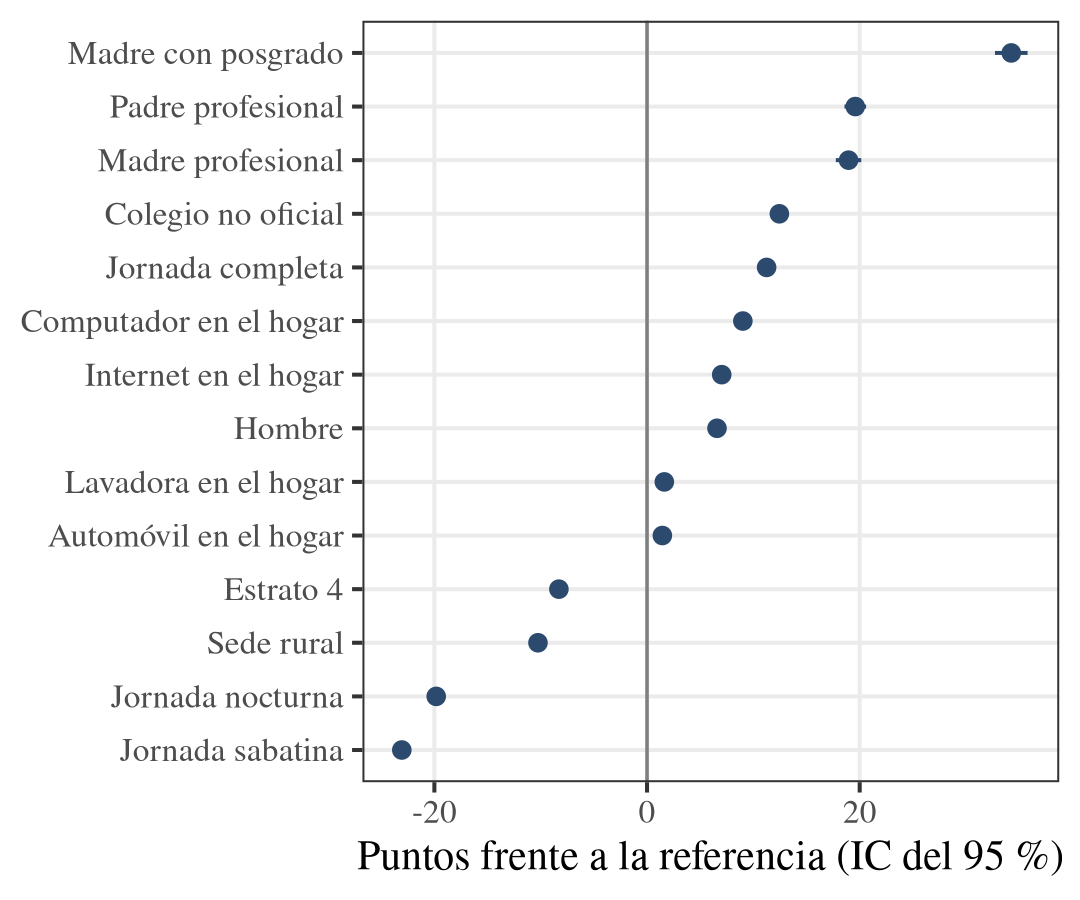

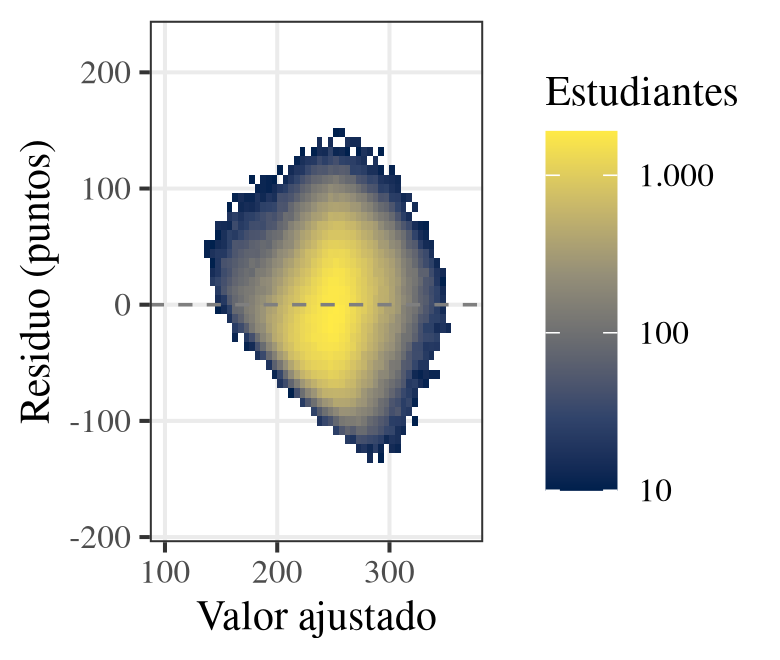

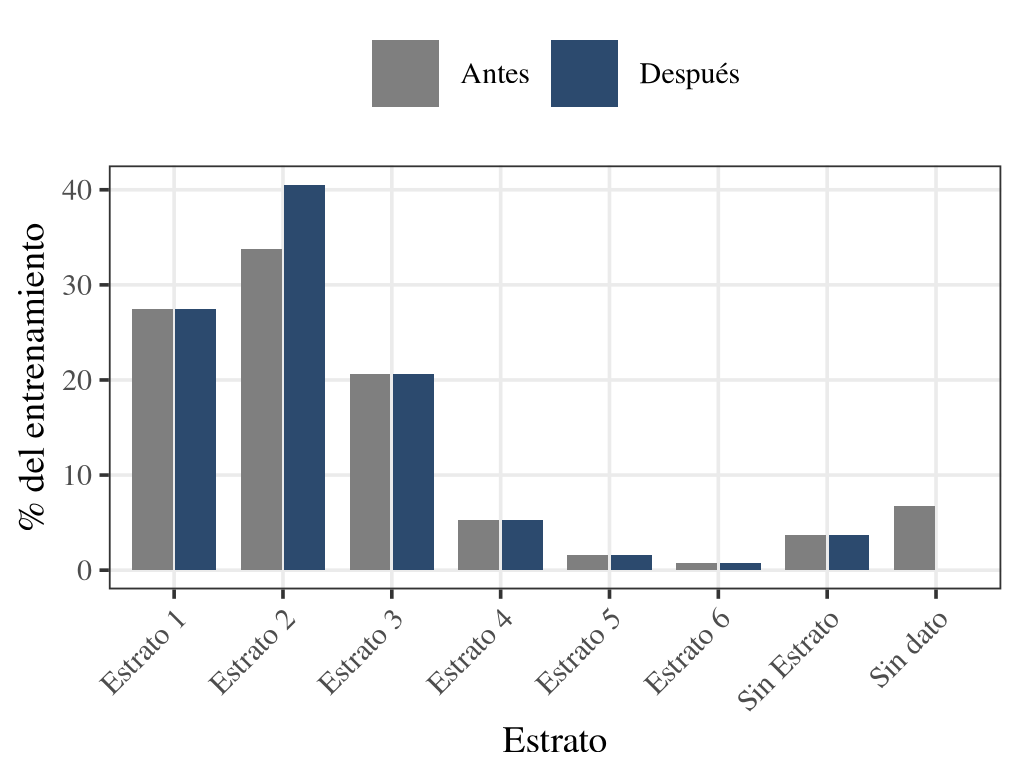

In [32]:
for nombre in ("coeficientes", "residuos", "laboratorio-estrato"):
    ruta = RUTA_FIGURAS / "r" / f"{nombre}-ggplot2.png"
    figuras.registrar(ruta)
    display(Image(filename=ruta, width=360))

**Lectura.** Las dos implementaciones llegan a los mismos números: los coeficientes de `lm` y de statsmodels coinciden hasta el ruido de la aritmética de punto flotante, igual que el R² y los descriptivos, y las frecuencias son idénticas. Eso confirma que R recibió el mismo entrenamiento, con las mismas referencias, y que la regresión no depende de la herramienta. Las tres figuras de ggplot2 dibujan los coeficientes, los residuos agrupados y el estrato antes y después de preparar; las dos primeras se comparan con las de Python en §16.

## 16. Herramientas de visualización para la regresión

### 16.1. Las dos figuras de la regresión en cuatro herramientas

La fase 1 comparó las herramientas con un histograma y un mapa de correlación. Aquí la comparación se hace con las dos figuras que más se usan para leer una regresión: los coeficientes con su intervalo de confianza del 95 % (los 14 términos de la múltiple que discute el informe) y los residuos frente a los valores ajustados, agrupados en celdas de 5 puntos de ajuste por 8 de residuo, con color en escala logarítmica y solo las celdas con 10 o más estudiantes. Matplotlib, Seaborn y Plotly dibujan las dos con la misma especificación que usa ggplot2 en `src/r/fase-2.R` (tamaño, títulos, celdas y umbral).

Para cada versión se mide lo mismo que en la fase 1: las instrucciones de la función que construye la figura, el tiempo de construirla y exportarla a PNG (mediana de tres corridas), el peso del PNG y el de una segunda salida (el PDF vectorial en Matplotlib, Seaborn y ggplot2, y el HTML interactivo en Plotly). Los tiempos y los pesos dependen de la máquina, así que sus macros llevan el prefijo `medida`.

Una diferencia de fondo aparece antes de medir. Seaborn no dibuja intervalos ya calculados: su `pointplot` estima el intervalo a partir de los datos, así que la función le entrega, para cada término, el límite inferior, el coeficiente y el límite superior, y le pide la mediana como punto y el mínimo y el máximo como barra. Plotly, por su parte, construye su histograma bidimensional en el navegador y guardaría en el HTML el par (ajustado, residuo) de cada uno de los 372.792 estudiantes; por eso su función agrupa las celdas con NumPy y le entrega a Plotly solo los conteos, y el HTML publicado no contiene ningún valor individual.

[ok] Los términos de la figura de coeficientes están en la múltiple


                         Instrucciones Tiempo a PNG (s) PNG (kB)   Segunda salida Segunda salida (kB)
Gráfico      Herramienta                                                                             
coeficientes Matplotlib              5            0,084  103,215    PDF vectorial              19,178
             Seaborn                 6            0,091  103,275    PDF vectorial              19,002
             Plotly                  5            1,750  128,525 HTML interactivo              10,893
             ggplot2                 1            0,091   84,048    PDF vectorial               5,785
residuos     Matplotlib              6            0,095   46,141    PDF vectorial              55,533
             Seaborn                 5            0,208   47,714    PDF vectorial              55,698
             Plotly                  7            1,764   67,117 HTML interactivo              76,454
             ggplot2                 1            0,266   38,800    PDF vectorial 

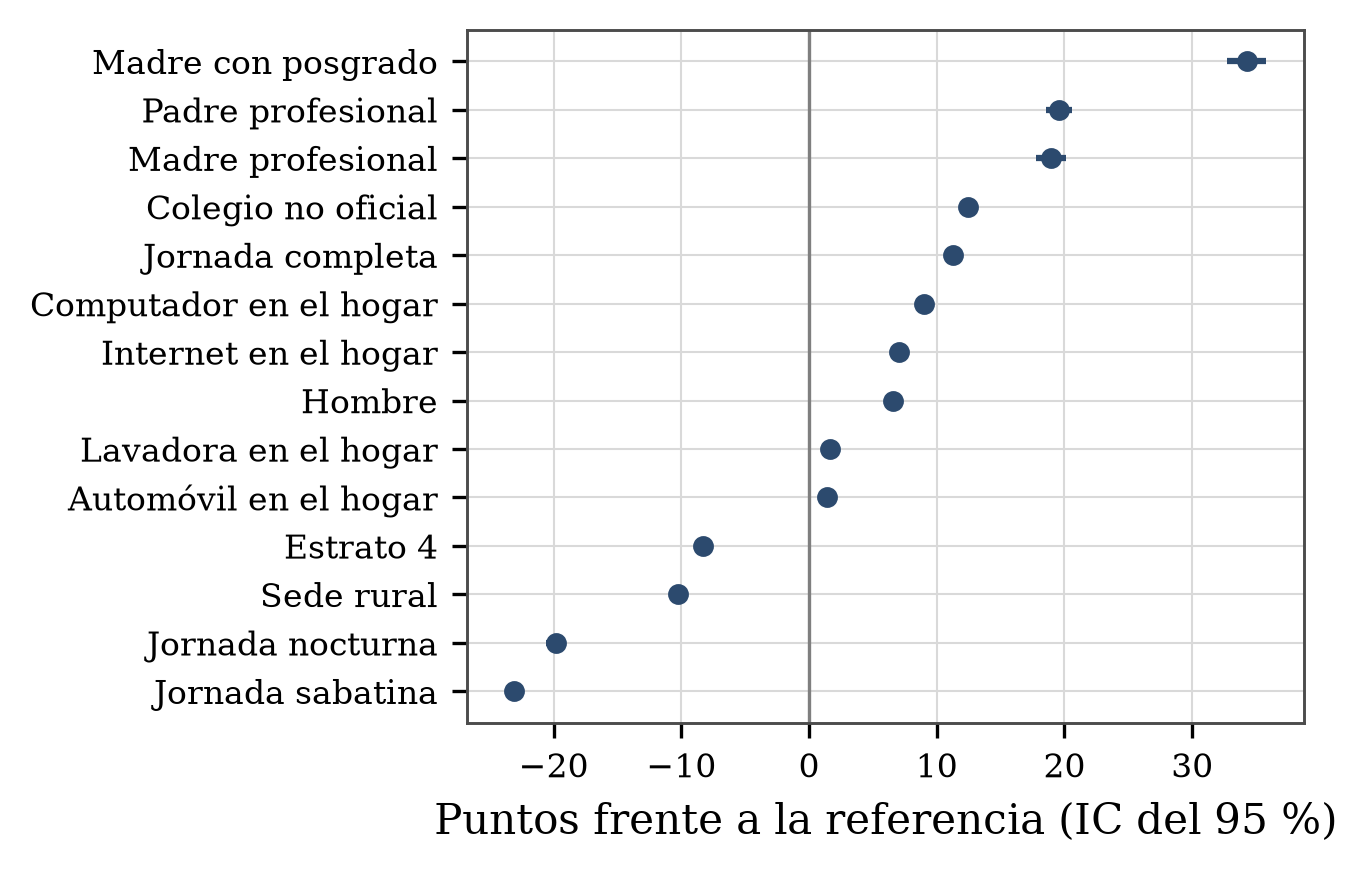

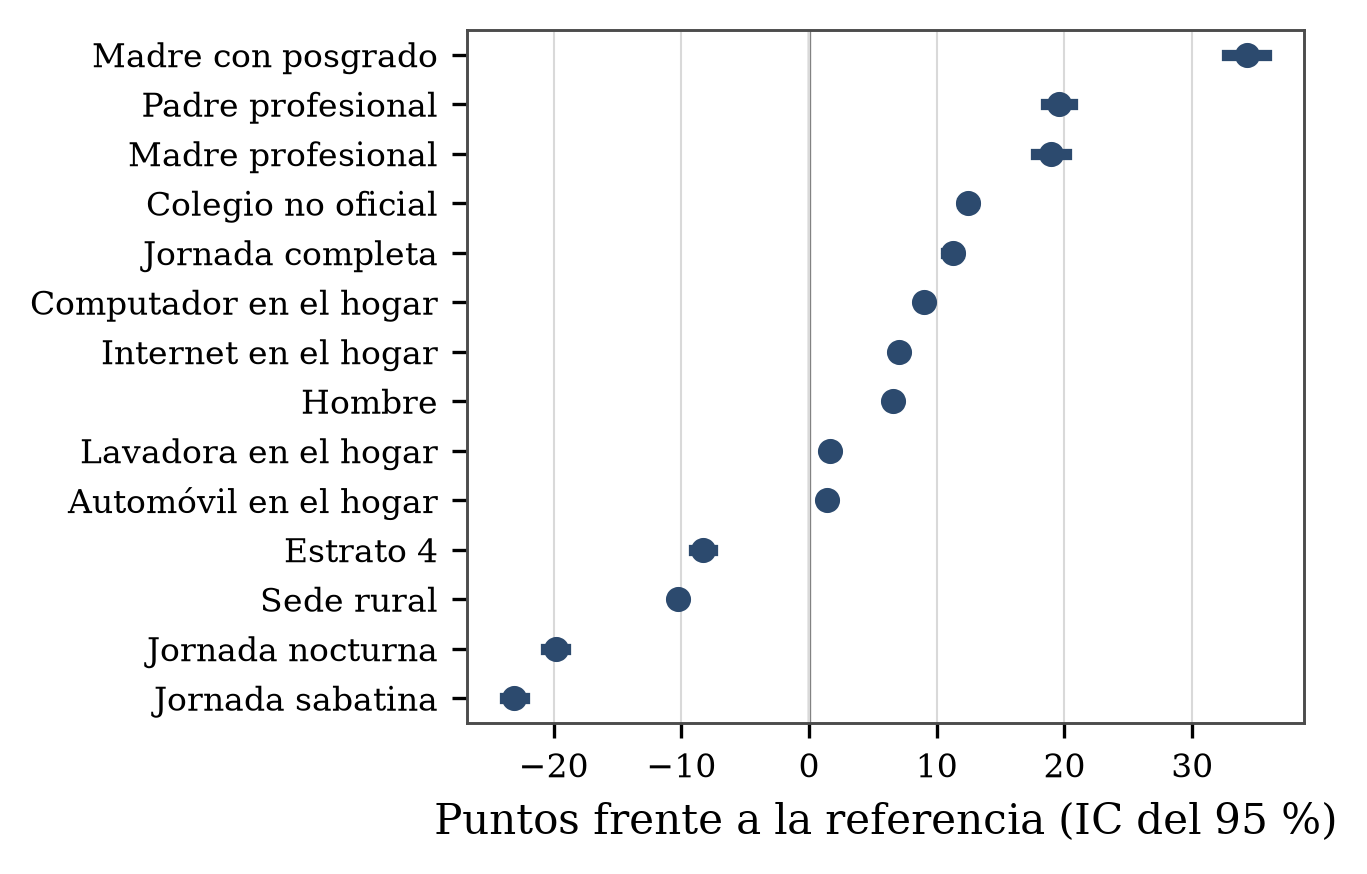

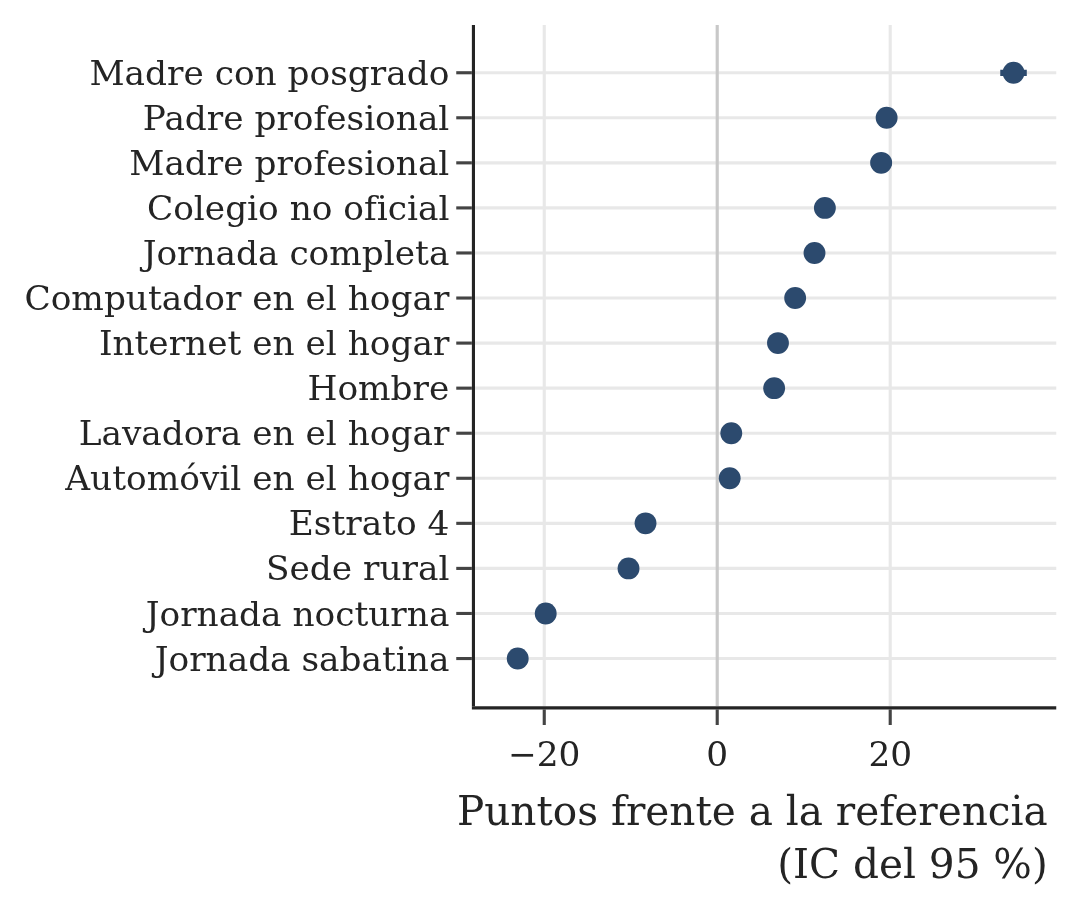

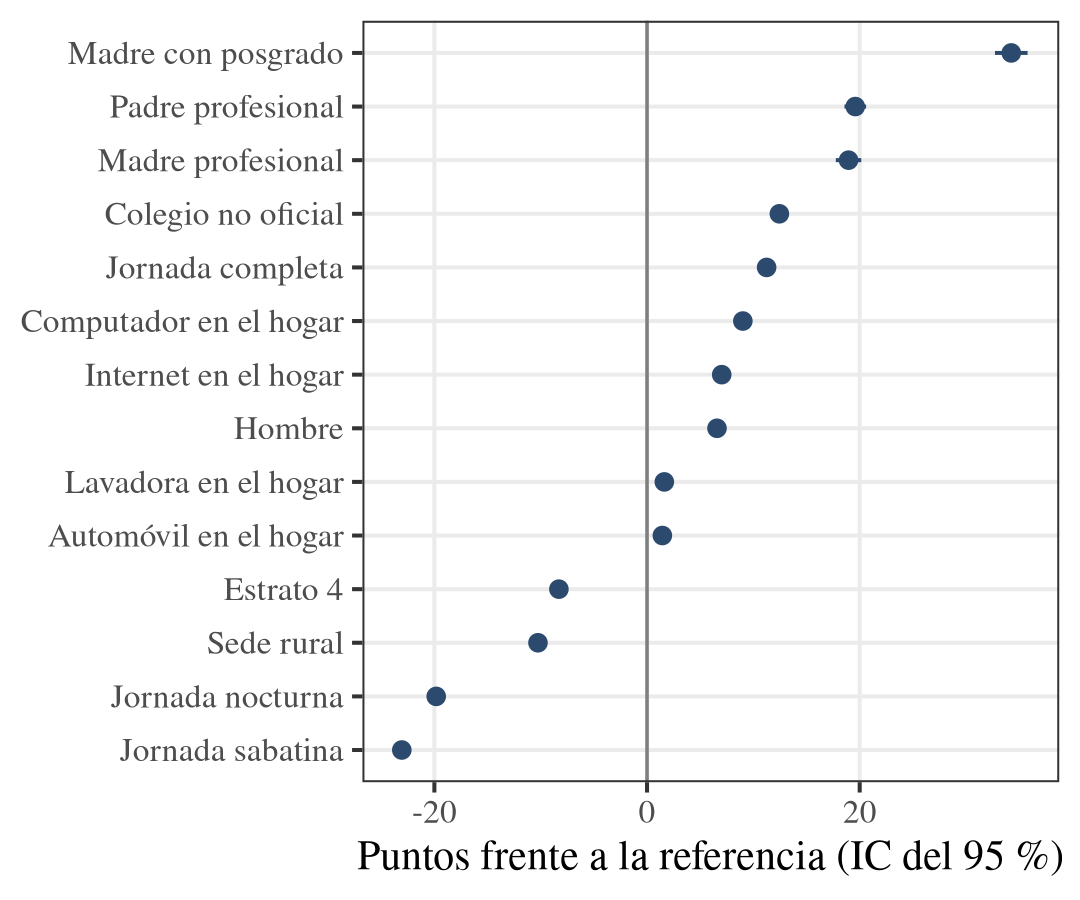

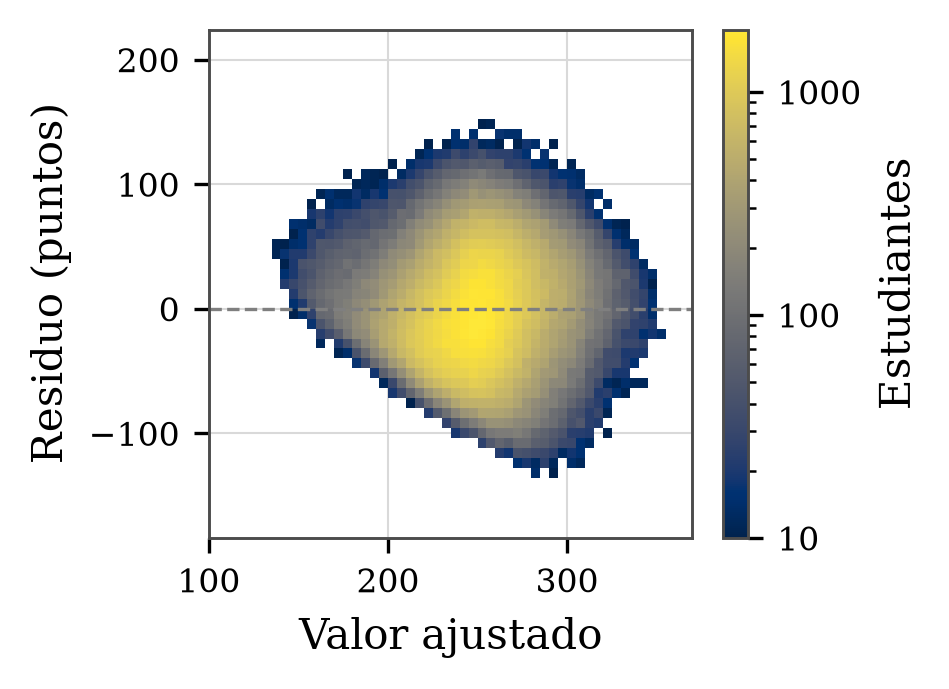

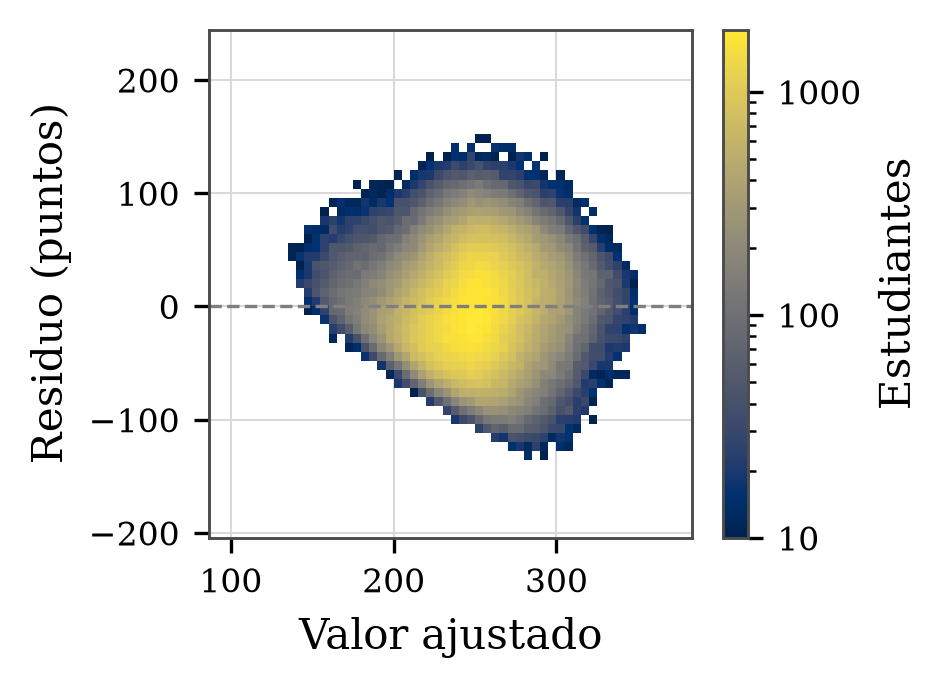

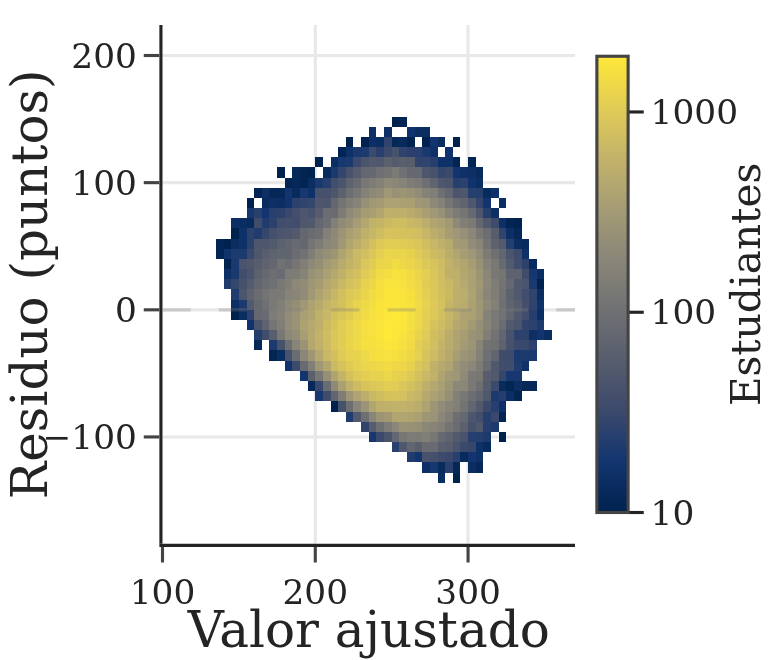

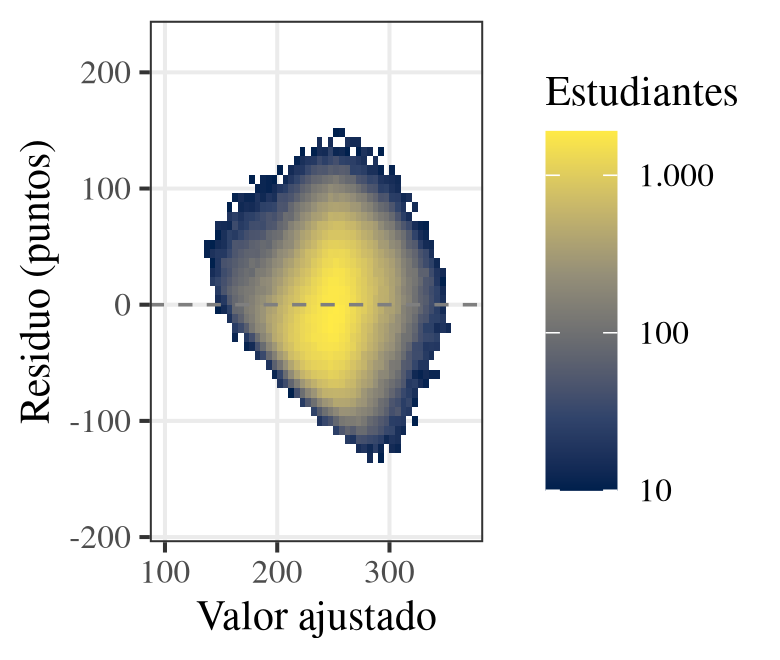

In [33]:
TAMANO_COEFICIENTES = (3.6, 3.0)
TAMANO_RESIDUOS = (2.6, 2.2)
ANCHO_AJUSTADO, ANCHO_RESIDUO = 5, 8
MINIMO_POR_CELDA = 10
TITULO_COEFICIENTES = "Puntos frente a la referencia (IC del 95 %)"
# ggplot2 usa letra de 10 puntos en los títulos y de 8 en las marcas; Plotly mide en píxeles a
# 96 por pulgada, así que 10 puntos son unos 13 píxeles.
ESTILO_HERRAMIENTAS = {"font.size": 10, "axes.labelsize": 10, "xtick.labelsize": 8, "ytick.labelsize": 8}
LETRA_PLOTLY = {"family": "DejaVu Serif", "size": 13}
MARCAS_PLOTLY = {"size": 11}
RUTA_HERRAMIENTAS = RUTA_FIGURAS / "herramientas"
RUTA_HERRAMIENTAS.mkdir(exist_ok=True)

comprobar("Los términos de la figura de coeficientes están en la múltiple", set(intermedios.TERMINOS_FIGURA) <= set(coeficientes.index))
coeficientes_figura = (
    coeficientes.loc[list(intermedios.TERMINOS_FIGURA), ["coeficiente", "ic_inferior", "ic_superior"]]
    .assign(etiqueta=lambda marco: marco.index.map(intermedios.TERMINOS_FIGURA))
    .sort_values("coeficiente")
)
residuos_figura = pd.DataFrame({"ajustado": ajustados.to_numpy(), "residuo": residuos.to_numpy()})


def bordes(valores: pd.Series, ancho: float) -> np.ndarray:
    return np.arange(np.floor(valores.min() / ancho) * ancho, valores.max() + ancho, ancho)


BORDES_AJUSTADO = bordes(residuos_figura["ajustado"], ANCHO_AJUSTADO)
BORDES_RESIDUO = bordes(residuos_figura["residuo"], ANCHO_RESIDUO)


def coeficientes_matplotlib(tabla: pd.DataFrame) -> plt.Figure:
    figura, eje = plt.subplots(figsize=TAMANO_COEFICIENTES)
    eje.axvline(0, color=graficos.COLOR_APOYO, linewidth=0.8)
    eje.errorbar(tabla["coeficiente"], tabla["etiqueta"], xerr=[tabla["coeficiente"] - tabla["ic_inferior"], tabla["ic_superior"] - tabla["coeficiente"]], fmt="o", markersize=4, color=graficos.COLOR_PRINCIPAL)
    eje.set_xlabel(TITULO_COEFICIENTES)
    return figura


def coeficientes_seaborn(tabla: pd.DataFrame) -> plt.Figure:
    largo = tabla.melt(id_vars="etiqueta", value_vars=["ic_inferior", "coeficiente", "ic_superior"], value_name="puntos")
    figura, eje = plt.subplots(figsize=TAMANO_COEFICIENTES)
    sns.pointplot(data=largo, x="puntos", y="etiqueta", order=tabla["etiqueta"][::-1], estimator="median", errorbar=lambda valores: (valores.min(), valores.max()), linestyle="none", markersize=4, color=graficos.COLOR_PRINCIPAL, ax=eje)
    eje.axvline(0, color=graficos.COLOR_APOYO, linewidth=0.8, zorder=0)
    eje.set(xlabel=TITULO_COEFICIENTES, ylabel="")
    return figura


def coeficientes_plotly(tabla: pd.DataFrame) -> go.Figure:
    figura = go.Figure(go.Scatter(
        x=tabla["coeficiente"], y=tabla["etiqueta"], mode="markers", marker={"color": graficos.COLOR_PRINCIPAL, "size": 7},
        error_x={"type": "data", "array": tabla["ic_superior"] - tabla["coeficiente"], "arrayminus": tabla["coeficiente"] - tabla["ic_inferior"], "width": 0, "color": graficos.COLOR_PRINCIPAL},
        customdata=tabla[["ic_inferior", "ic_superior"]], hovertemplate="%{y}: %{x:.1f} puntos (IC del 95 %: %{customdata[0]:.1f} a %{customdata[1]:.1f})<extra></extra>",
    ))
    figura.add_vline(x=0, line={"color": graficos.COLOR_APOYO, "width": 1})
    figura.add_annotation(text=TITULO_COEFICIENTES.replace(" (", "<br>("), xref="paper", x=1, xanchor="right", yref="paper", y=0, yanchor="top", yshift=-24, align="right", showarrow=False)
    figura.update_layout(
        template="simple_white", width=TAMANO_COEFICIENTES[0] * graficos.PUNTOS_POR_PULGADA_PLOTLY, height=TAMANO_COEFICIENTES[1] * graficos.PUNTOS_POR_PULGADA_PLOTLY,
        xaxis={"showgrid": True, "tickfont": MARCAS_PLOTLY}, yaxis={"showgrid": True, "automargin": True, "tickfont": MARCAS_PLOTLY},
        separators=",.", font=LETRA_PLOTLY, margin={"l": 8, "r": 8, "t": 8, "b": 62}, showlegend=False,
    )
    return figura


def residuos_matplotlib(tabla: pd.DataFrame) -> plt.Figure:
    figura, eje = plt.subplots(figsize=TAMANO_RESIDUOS)
    *_, malla = eje.hist2d(tabla["ajustado"], tabla["residuo"], bins=[BORDES_AJUSTADO, BORDES_RESIDUO], cmin=MINIMO_POR_CELDA, cmap="cividis", norm=LogNorm())
    eje.axhline(0, color=graficos.COLOR_APOYO, linestyle="--", linewidth=0.8)
    eje.set(xlabel="Valor ajustado", ylabel="Residuo (puntos)")
    figura.colorbar(malla, ax=eje, label="Estudiantes", format=graficos.FORMATO_MILES)
    return figura


def residuos_seaborn(tabla: pd.DataFrame) -> plt.Figure:
    figura, eje = plt.subplots(figsize=TAMANO_RESIDUOS)
    sns.histplot(data=tabla, x="ajustado", y="residuo", bins=[BORDES_AJUSTADO, BORDES_RESIDUO], thresh=MINIMO_POR_CELDA - 1, cmap="cividis", norm=LogNorm(), vmin=None, vmax=None, cbar=True, cbar_kws={"label": "Estudiantes", "format": graficos.FORMATO_MILES}, ax=eje)
    eje.axhline(0, color=graficos.COLOR_APOYO, linestyle="--", linewidth=0.8)
    eje.set(xlabel="Valor ajustado", ylabel="Residuo (puntos)")
    return figura


def residuos_plotly(tabla: pd.DataFrame) -> go.Figure:
    conteos, _, _ = np.histogram2d(tabla["ajustado"], tabla["residuo"], bins=[BORDES_AJUSTADO, BORDES_RESIDUO])
    visibles = np.where(conteos >= MINIMO_POR_CELDA, conteos, np.nan).T
    potencias = np.arange(1, int(np.log10(np.nanmax(visibles))) + 1)
    figura = go.Figure(go.Heatmap(
        x=BORDES_AJUSTADO[:-1] + ANCHO_AJUSTADO / 2, y=BORDES_RESIDUO[:-1] + ANCHO_RESIDUO / 2, z=np.log10(visibles), customdata=visibles, colorscale="Cividis",
        colorbar={"title": {"text": "Estudiantes", "side": "right"}, "tickvals": potencias, "ticktext": [en_espanol(10**p) for p in potencias], "thickness": 10, "xpad": 4, "tickfont": MARCAS_PLOTLY},
        hovertemplate="Ajustado %{x} y residuo %{y}: %{customdata:,.0f} estudiantes<extra></extra>",
    ))
    figura.add_hline(y=0, line={"color": graficos.COLOR_APOYO, "width": 1, "dash": "dash"})
    figura.update_layout(
        template="simple_white", width=TAMANO_RESIDUOS[0] * graficos.PUNTOS_POR_PULGADA_PLOTLY, height=TAMANO_RESIDUOS[1] * graficos.PUNTOS_POR_PULGADA_PLOTLY,
        xaxis={"title": {"text": "Valor ajustado", "standoff": 4}, "showgrid": True, "dtick": 100, "tickfont": MARCAS_PLOTLY}, yaxis={"title": {"text": "Residuo (puntos)", "standoff": 2}, "showgrid": True, "tickfont": MARCAS_PLOTLY},
        separators=",.", font=LETRA_PLOTLY, margin={"l": 8, "r": 0, "t": 8, "b": 8},
    )
    return figura


GRAFICOS_HERRAMIENTAS = {
    "coeficientes": (coeficientes_figura, {"Matplotlib": coeficientes_matplotlib, "Seaborn": coeficientes_seaborn, "Plotly": coeficientes_plotly}),
    "residuos": (residuos_figura, {"Matplotlib": residuos_matplotlib, "Seaborn": residuos_seaborn, "Plotly": residuos_plotly}),
}
filas_medicion = []
with mpl.rc_context(ESTILO_HERRAMIENTAS):
    for grafico, (datos_grafico, funciones) in GRAFICOS_HERRAMIENTAS.items():
        for herramienta, construir in funciones.items():
            ruta_png = RUTA_HERRAMIENTAS / f"{grafico}-{herramienta.lower()}.png"
            filas_medicion.append({"Gráfico": grafico, "Herramienta": herramienta, **graficos.medir(construir, datos_grafico, ruta_png)})
            figuras.registrar(ruta_png)
        ruta_html = RUTA_HERRAMIENTAS / f"{grafico}-plotly.html"
        graficos.exportar(funciones["Plotly"](datos_grafico), ruta_html)
        figuras.registrar(ruta_html)
for grafico, medida in salida_r["medicion"].items():
    filas_medicion.append({
        "Gráfico": grafico, "Herramienta": "ggplot2", "Instrucciones": medida["instrucciones"], "Tiempo a PNG (s)": medida["tiempo_s"],
        "PNG (kB)": medida["png_kb"], "Segunda salida": "PDF vectorial", "Segunda salida (kB)": medida["pdf_kb"],
    })
medicion = pd.DataFrame(filas_medicion).set_index(["Gráfico", "Herramienta"]).sort_index(level=0, sort_remaining=False)
tabla(medicion, 3)
for grafico, medida in salida_r["medicion"].items():
    print(f"ggplot2 ({grafico}): {medida['componentes']} componentes encadenados con + en {medida['instrucciones']} instrucción")
pesos_html = {grafico: (RUTA_HERRAMIENTAS / f"{grafico}-plotly.html").stat().st_size / 1024 for grafico in GRAFICOS_HERRAMIENTAS}
print("HTML publicados: " + "; ".join(f"{grafico}-plotly.html, {en_espanol(peso, 1)} kB" for grafico, peso in pesos_html.items()))

comprobar(
    "Comparación medida: cuatro herramientas en las dos figuras, con tiempo y pesos positivos",
    len(medicion) == 8 and (medicion[["Tiempo a PNG (s)", "PNG (kB)", "Segunda salida (kB)"]] > 0).all().all(),
)
comprobar("Comparación medida: el HTML de los residuos solo trae celdas agrupadas (pesa menos de 100 kB)", pesos_html["residuos"] < 100)
SUFIJO_GRAFICO = {"coeficientes": "Coef", "residuos": "Resid"}
SUFIJO_HERRAMIENTA = {"Matplotlib": "Matplotlib", "Seaborn": "Seaborn", "Plotly": "Plotly", "ggplot2": "Ggplot"}
for (grafico, herramienta), fila in medicion.iterrows():
    sufijo = SUFIJO_GRAFICO[grafico] + SUFIJO_HERRAMIENTA[herramienta]
    cifra(f"medidaInstrucciones{sufijo}", fila["Instrucciones"])
    cifra(f"medidaTiempo{sufijo}", fila["Tiempo a PNG (s)"], 2)
    cifra(f"medidaPng{sufijo}", fila["PNG (kB)"], 0)
    cifra(f"medidaSegunda{sufijo}", fila["Segunda salida (kB)"], 0)
for grafico, medida in salida_r["medicion"].items():
    cifra(f"medidaComponentes{SUFIJO_GRAFICO[grafico]}Ggplot", medida["componentes"])
for grafico, peso in pesos_html.items():
    cifra(f"medidaHtml{SUFIJO_GRAFICO[grafico]}", peso, 0)
cifra("terminosFiguraCoeficientes", len(coeficientes_figura))

for grafico in GRAFICOS_HERRAMIENTAS:
    for herramienta in ("matplotlib", "seaborn", "plotly"):
        display(Image(filename=RUTA_HERRAMIENTAS / f"{grafico}-{herramienta}.png", width=300))
    display(Image(filename=RUTA_FIGURAS / "r" / f"{grafico}-ggplot2.png", width=300))

**Lectura.** Las cuatro herramientas llegan a las mismas dos figuras; sus diferencias están en cómo se escribe cada una y en lo que cuesta su salida.

- **Matplotlib** obliga a declarar cada elemento (la línea del cero, las barras de error, la barra de color), pero dibuja sin rodeos los intervalos que ya calculó statsmodels y las celdas bidimensionales.
- **Seaborn** gana cuando el gráfico es una estimación sobre los datos crudos: su `histplot` bidimensional resuelve el umbral de 10 estudiantes con un parámetro (`thresh`). Pierde cuando los intervalos ya vienen calculados, porque hay que darles una forma artificial para que los dibuje. Además, su barra de error es más gruesa por defecto y deja ver intervalos que en Matplotlib quedan tapados por el punto.
- **Plotly** tarda segundos en exportar cada PNG, frente a décimas en las demás, porque lo hace a través de un navegador sin interfaz (Kaleido), y no ensancha el lienzo cuando el título del eje no cabe: hubo que partirlo y llevarlo a una anotación. A cambio, su HTML es la única salida interactiva: al pasar el cursor muestra el intervalo de cada coeficiente o los estudiantes de cada celda. Por eso es la biblioteca del dashboard.
- **ggplot2** encadena la figura en una sola expresión con `+`; su número de componentes es comparable con las instrucciones de las bibliotecas de Python, y sus PDF son los más livianos.

Para un informe impreso bastan Matplotlib o ggplot2; Plotly se reserva para el dashboard, donde la interactividad sí se aprovecha.

### 16.2. La arquitectura de Matplotlib en el panel de diagnóstico

Matplotlib tiene tres capas: el *backend*, que dibuja en un formato o en una pantalla; los artistas, donde todo lo visible es un objeto `Artist`; y `pyplot`, la capa de *scripting*. Dentro de los artistas la jerarquía es fija: una `Figure` contiene uno o más `Axes`, y cada `Axes` contiene los artistas que dibujan. La fase 1 recorrió esa jerarquía en un histograma; aquí se recorre en el panel de diagnóstico de §12, que se construyó con la interfaz orientada a objetos, y se confirma que el método `plot` de pandas devuelve un `Axes` de Matplotlib.

In [34]:
ancho_panel, alto_panel = figura_diagnostico.get_size_inches()
print(f"Backend en uso: {mpl.get_backend()}")
print(f"Figure: {type(figura_diagnostico).__module__}.{type(figura_diagnostico).__name__} de {en_espanol(ancho_panel, 1)} × {en_espanol(alto_panel, 1)} pulgadas, con {len(figura_diagnostico.axes)} Axes")
for eje in figura_diagnostico.axes:
    tipos = Counter(type(artista).__name__ for artista in eje.get_children())
    print(f"  {eje.get_title()}: " + ", ".join(f"{n} {tipo}" for tipo, n in tipos.most_common()))
artistas_panel = [artista for eje in figura_diagnostico.axes for artista in eje.get_children()]
eje_pandas = residuos.plot.hist(bins=60, color=graficos.COLOR_APOYO)
print(f"\nSeries.plot.hist devuelve: {type(eje_pandas).__module__}.{type(eje_pandas).__name__}")
plt.close(eje_pandas.figure)
comprobar("El panel de diagnóstico es una Figure con cuatro Axes", len(figura_diagnostico.axes) == 4)
comprobar(f"Los {len(artistas_panel)} hijos de los cuatro Axes son objetos Artist", all(isinstance(artista, Artist) for artista in artistas_panel))
comprobar("pandas grafica a través de Matplotlib", isinstance(eje_pandas, mpl.axes.Axes))
cifra("artistasPanel", len(artistas_panel))

Backend en uso: module://matplotlib_inline.backend_inline
Figure: matplotlib.figure.Figure de 7,2 × 5,4 pulgadas, con 4 Axes
  (a) Residuos frente a ajustados: 4 Spine, 3 Text, 2 Line2D, 1 PolyCollection, 1 XAxis, 1 YAxis, 1 Legend, 1 Rectangle
  (b) Cuantil-cuantil (1.000 cuantiles): 4 Spine, 3 Text, 1 PathCollection, 1 Line2D, 1 XAxis, 1 YAxis, 1 Rectangle
  (c) Distribución de la distancia de Cook: 61 Rectangle, 4 Spine, 3 Text, 1 Line2D, 1 Annotation, 1 XAxis, 1 YAxis, 1 Legend
  (d) Escala y ubicación: 4 Spine, 3 Text, 1 PolyCollection, 1 Line2D, 1 XAxis, 1 YAxis, 1 Rectangle

Series.plot.hist devuelve: matplotlib.axes._axes.Axes
[ok] El panel de diagnóstico es una Figure con cuatro Axes
[ok] Los 111 hijos de los cuatro Axes son objetos Artist
[ok] pandas grafica a través de Matplotlib


'111'

### 16.3. Frameworks para el dashboard

El dashboard de la fase 2 (§17) se construye en Streamlit. La tabla resume por qué, frente a las otras tres opciones que proponen las lecturas de la actividad 4 y la unidad 2 del curso.

| Framework | Lenguaje | Cómo se construye la aplicación | Publicación | Encaje con este proyecto |
| --- | --- | --- | --- | --- |
| Streamlit | Python | Un *script* que se vuelve a ejecutar de arriba abajo con cada interacción; los filtros son funciones que devuelven el valor elegido | Streamlit Community Cloud, gratis desde un repositorio público de GitHub | Elegido: el modelo y los agregados salen de Python, la app cabe en un archivo y se despliega desde el mismo repositorio |
| Dash | Python | Un diseño de componentes y funciones *callback* que conectan entradas con salidas | Un servidor propio, porque una app de Dash es una aplicación web de Flask | Más control del diseño y de los filtros cruzados entre gráficos, a cambio de más código; es la alternativa si el tablero crece en la fase 4 |
| Shiny con shinydashboard | R | Programación reactiva: una interfaz (`ui`) y una función de servidor que recalcula lo que depende de cada entrada | shinyapps.io o un servidor propio | Obligaría a mantener la app en R, cuando el `Pipeline` y los agregados salen de Python |
| Bold BI | Sin código | Tableros armados en un diseñador web, pensados para incrustarse en otras aplicaciones | Servicio en la nube o instalación propia, con licencia comercial | El tablero no queda como código en el repositorio, y con eso se pierde la reproducibilidad que el proyecto exige |

## 17. Agregados para el dashboard

El dashboard (`dashboard/app.py`) solo lee archivos de `data/agregados/`, nunca los recortes con filas individuales. La fase 1 dejó la serie por estrato y naturaleza y el resumen por departamento; esta fase agrega cinco archivos del 2022-2, con los 532.561 estudiantes del análisis:

- **`estrato-naturaleza-zona-20224.csv`:** el cruce completo de estrato (con "Sin dato" para quienes no lo declararon), naturaleza y zona del colegio, más sus marginales, en las que la dimensión que no se filtra vale "Todos". Así cada combinación de filtros tiene su mediana exacta, que no se puede reconstruir sumando celdas.
- **`departamento-zona-20224.csv`:** departamento por zona, con la zona también en "Todos".
- **`distribucion-puntaje-20224.csv`:** estudiantes por intervalo de 10 puntos del puntaje global, por naturaleza y zona (con sus marginales). Los intervalos de los extremos quedan abiertos ("menos de" y "o más") hasta que todas las celdas lleguen a 10.
- **`regresion-coeficientes.csv`:** los coeficientes de la múltiple con su intervalo clásico y con el agrupado por departamento (salvo en los términos del propio departamento, donde ese error no es confiable), con `n` igual al número de estudiantes de entrenamiento que tienen ese nivel (o ese faltante).
- **`regresion-grupos.csv`:** el puntaje observado y el predicho en validación, por estrato y naturaleza; si una celda no llegara a 10, el archivo quedaría solo por estrato.
- **`regresion-metricas.csv`:** R², RMSE y MAE de los tres modelos de regresión en entrenamiento, validación y prueba.

La regla es la de la fase 1: **cada archivo es un cruce completo con 10 o más estudiantes en todas sus celdas, sin supresión.** Una celda oculta se podría recuperar restando de los totales, así que el cruce que no cumple no se publica. Por eso no hay un archivo de departamento por naturaleza: una de sus celdas tiene 3 estudiantes, y el dashboard dice que esa combinación no está publicada. Las medidas se redondean a dos decimales y las métricas de los modelos, a cuatro.

In [35]:
RUTA_AGREGADOS = datos.DESTINO / "agregados"
MINIMO_AGREGADO = 10
TODOS, SIN_DATO = "Todos", "Sin dato"
MEDIDAS_PUNTAJE = {
    "n": "size",
    "media": "mean",
    "mediana": "median",
    "q1": lambda serie: serie.quantile(0.25),
    "q3": lambda serie: serie.quantile(0.75),
    "desviacion": "std",
}
NOMBRE_VARIABLE = {
    v.ESTRATO: "Estrato", v.EDUCACION_MADRE: "Educación de la madre", v.EDUCACION_PADRE: "Educación del padre",
    "FAMI_TIENEINTERNET": "Internet", "FAMI_TIENECOMPUTADOR": "Computador", "FAMI_TIENEAUTOMOVIL": "Automóvil", "FAMI_TIENELAVADORA": "Lavadora",
    v.CUARTOS_HOGAR: "Cuartos del hogar", v.PERSONAS_HOGAR: "Personas del hogar", v.INDICE_BIENES: "Índice de bienes", v.EDUCACION_MAXIMA: "Máxima educación de los padres", v.HACINAMIENTO: "Hacinamiento",
    "COLE_NATURALEZA": "Naturaleza del colegio", "COLE_AREA_UBICACION": "Zona de la sede", "COLE_JORNADA": "Jornada", "COLE_CALENDARIO": "Calendario",
    "COLE_CARACTER": "Carácter del colegio", "COLE_BILINGUE": "Colegio bilingüe", "COLE_GENERO": "Género del colegio", v.DEPARTAMENTO: "Departamento",
    "ESTU_GENERO": "Género del estudiante", v.EDAD: "Edad",
}
NOMBRE_MODELO = {"dummyRegresion": "Media del entrenamiento", "linealSimple": "Lineal simple", "regresionMultiple": "Regresión múltiple"}


def cubo(marco: pd.DataFrame, dimensiones: list[str], medidas: dict, fijas: tuple[str, ...] = ()) -> pd.DataFrame:
    """Cruce completo de las dimensiones más sus marginales, con «Todos» en la dimensión que no se agrupa."""
    partes = []
    for tamano in range(len(dimensiones), -1, -1):
        for agrupadas in combinations(dimensiones, tamano):
            vista = marco.assign(**{d: TODOS for d in dimensiones if d not in agrupadas})
            partes.append(vista.groupby([*fijas, *dimensiones], observed=True)["puntaje"].agg(**medidas).reset_index())
    return pd.concat(partes, ignore_index=True)


def es_cruce_completo(marco: pd.DataFrame, dimensiones: list[str]) -> bool:
    return len(marco) == int(np.prod([marco[d].nunique() for d in dimensiones])) and not marco.duplicated(dimensiones).any()


analisis = pd.DataFrame({
    "estrato": limpio[v.ESTRATO].fillna(SIN_DATO),
    "naturaleza": limpio["COLE_NATURALEZA"],
    "zona": limpio["COLE_AREA_UBICACION"],
    "cod_depto": limpio["COLE_COD_DEPTO_UBICACION"],
    "departamento": limpio[v.DEPARTAMENTO],
    "puntaje": limpio[v.OBJETIVO_REGRESION],
})
comprobar("Las dimensiones de los agregados no tienen faltantes, salvo el estrato, que va como «Sin dato»", not analisis.drop(columns="estrato").isna().any().any())

estrato_naturaleza_zona = cubo(analisis, ["estrato", "naturaleza", "zona"], MEDIDAS_PUNTAJE)
departamento_zona = cubo(analisis, ["zona"], MEDIDAS_PUNTAJE, fijas=("cod_depto", "departamento"))

# Intervalos de 10 puntos. Cada extremo abierto crece mientras él, o el primer intervalo cerrado
# a su lado, tenga alguna celda de naturaleza y zona con menos de 10 estudiantes.
ANCHO_INTERVALO = 10
celda_base = (analisis["puntaje"] // ANCHO_INTERVALO * ANCHO_INTERVALO).clip(upper=500 - ANCHO_INTERVALO).astype(int)
por_celda = pd.crosstab(celda_base, [analisis["naturaleza"], analisis["zona"]]).reindex(range(0, 500, ANCHO_INTERVALO), fill_value=0)
limite_bajo, limite_alto = ANCHO_INTERVALO, 500 - ANCHO_INTERVALO
while (por_celda.loc[: limite_bajo - ANCHO_INTERVALO].sum() < MINIMO_AGREGADO).any() or (por_celda.loc[limite_bajo] < MINIMO_AGREGADO).any():
    limite_bajo += ANCHO_INTERVALO
while (por_celda.loc[limite_alto:].sum() < MINIMO_AGREGADO).any() or (por_celda.loc[limite_alto - ANCHO_INTERVALO] < MINIMO_AGREGADO).any():
    limite_alto -= ANCHO_INTERVALO
desde = celda_base.clip(lower=limite_bajo - ANCHO_INTERVALO, upper=limite_alto).where(celda_base >= limite_bajo, 0)
analisis["desde"] = desde.astype(int)
analisis["hasta"] = np.where(desde >= limite_alto, 500, np.where(desde == 0, limite_bajo - 1, desde + ANCHO_INTERVALO - 1)).astype(int)
analisis["intervalo"] = np.where(desde == 0, f"Menos de {limite_bajo}", np.where(desde >= limite_alto, f"{limite_alto} o más", analisis["desde"].astype(str) + " a " + analisis["hasta"].astype(str)))
distribucion = cubo(analisis, ["naturaleza", "zona"], {"n": "size"}, fijas=("desde", "hasta", "intervalo"))
print(f"Distribución del puntaje: intervalos de {ANCHO_INTERVALO} puntos entre {limite_bajo} y {limite_alto}, con los extremos abiertos")

# Coeficientes de la múltiple, con los estudiantes de entrenamiento de cada nivel.
filas_coeficientes = []
for termino, fila in coeficientes.drop(index="Intercept").iterrows():
    variable, _, nivel = termino.partition("=")
    if nivel:
        n_termino = int(preparado[variable].eq(nivel).sum())
    elif v.es_indicador(termino):
        n_termino = int(preparado[termino].sum())
    else:
        n_termino = len(preparado)
    base = variable.removeprefix(v.PREFIJO_FALTA)
    # El error agrupado por departamento no es confiable para los términos del propio departamento.
    error_agrupado = np.nan if variable == v.DEPARTAMENTO else errores.loc[termino, "agrupado por departamento"]
    filas_coeficientes.append({
        "termino": termino, "bloque": bloque(termino),
        "variable": f"Sin dato: {NOMBRE_VARIABLE[base]}" if v.es_indicador(termino) else NOMBRE_VARIABLE[variable],
        "nivel": nivel, "coeficiente": fila["coeficiente"], "ic_inferior": fila["ic_inferior"], "ic_superior": fila["ic_superior"],
        "ic_agrupado_inferior": fila["coeficiente"] - 1.96 * error_agrupado, "ic_agrupado_superior": fila["coeficiente"] + 1.96 * error_agrupado,
        "n": n_termino,
    })
regresion_coeficientes = pd.DataFrame(filas_coeficientes)

# Observado frente a predicho en validación, por el estrato declarado y la naturaleza.
validacion_grupos = pd.DataFrame({
    "estrato": limpio.loc[es_val, v.ESTRATO].fillna(SIN_DATO).to_numpy(),
    "naturaleza": limpio.loc[es_val, "COLE_NATURALEZA"].to_numpy(),
    "observado": y_val.to_numpy(),
    "predicho": regresion.predict(X_val),
})
validacion_grupos["error_cuadrado"] = (validacion_grupos["observado"] - validacion_grupos["predicho"]) ** 2
dimensiones_grupos = ["estrato", "naturaleza"]
if validacion_grupos.groupby(dimensiones_grupos).size().min() < MINIMO_AGREGADO:
    dimensiones_grupos = ["estrato"]
regresion_grupos = validacion_grupos.groupby(dimensiones_grupos).agg(
    n=("observado", "size"), observado=("observado", "mean"), predicho=("predicho", "mean"), error_cuadrado=("error_cuadrado", "mean")
).reset_index()
regresion_grupos["rmse"] = np.sqrt(regresion_grupos.pop("error_cuadrado"))
print(f"Observado frente a predicho en validación, por {' y '.join(dimensiones_grupos)}")

filas_por_conjunto = {"entrenamiento": int(es_ent.sum()), "validación": int(es_val.sum()), "prueba": int(es_pru.sum())}
regresion_metricas = regresion_tres.reset_index(names=["modelo", "conjunto"]).assign(
    modelo=lambda marco: marco["modelo"].map(NOMBRE_MODELO), n=lambda marco: marco["conjunto"].map(filas_por_conjunto)
)[["modelo", "conjunto", "n", "r2", "rmse", "mae"]]

AGREGADOS = {
    "estrato-naturaleza-zona-20224.csv": (estrato_naturaleza_zona, ["estrato", "naturaleza", "zona"]),
    "departamento-zona-20224.csv": (departamento_zona, ["cod_depto", "zona"]),
    "distribucion-puntaje-20224.csv": (distribucion, ["intervalo", "naturaleza", "zona"]),
    "regresion-coeficientes.csv": (regresion_coeficientes, ["termino"]),
    "regresion-grupos.csv": (regresion_grupos, dimensiones_grupos),
    "regresion-metricas.csv": (regresion_metricas, ["modelo", "conjunto"]),
}
# Las medidas van con dos decimales; las métricas, con cuatro, para que el R² se lea con tres.
DECIMALES_AGREGADO = {"regresion-metricas.csv": 4}
RUTA_AGREGADOS.mkdir(parents=True, exist_ok=True)
for nombre, (agregado, dimensiones) in AGREGADOS.items():
    comprobar(f"{nombre}: cruce completo, con {MINIMO_AGREGADO} o más estudiantes en cada una de sus {len(agregado)} celdas", es_cruce_completo(agregado, dimensiones) and agregado["n"].min() >= MINIMO_AGREGADO)
    agregado.round(DECIMALES_AGREGADO.get(nombre, 2)).to_csv(RUTA_AGREGADOS / nombre, index=False)
    print(f"Escrito {relativa(RUTA_AGREGADOS / nombre)}: {len(agregado)} filas, la menor celda con {en_espanol(agregado['n'].min())} estudiantes")

total_cubo = estrato_naturaleza_zona.query("estrato == @TODOS and naturaleza == @TODOS and zona == @TODOS")["n"].item()
comprobar("Los marginales «Todos» suman los estudiantes del análisis", total_cubo == filas_analisis == departamento_zona.query("zona == @TODOS")["n"].sum() == distribucion.query("naturaleza == @TODOS and zona == @TODOS")["n"].sum())
comprobar("Los grupos de validación suman las filas de validación", regresion_grupos["n"].sum() == filas_por_conjunto["validación"])
cifra("limiteBajoDistribucion", limite_bajo)
cifra("limiteAltoDistribucion", limite_alto)
cifra("filasAgregadoCubo", len(estrato_naturaleza_zona))
cifra("celdaMinimaCubo", estrato_naturaleza_zona["n"].min())
cifra("celdaMinimaDepartamentoZona", departamento_zona["n"].min())
cifra("celdaMinimaCoeficientes", regresion_coeficientes["n"].min())
cifra("celdaMinimaGrupos", regresion_grupos["n"].min())
cifra("archivosAgregadosNuevos", len(AGREGADOS))

[ok] Las dimensiones de los agregados no tienen faltantes, salvo el estrato, que va como «Sin dato»


Distribución del puntaje: intervalos de 10 puntos entre 160 y 390, con los extremos abiertos


Observado frente a predicho en validación, por estrato y naturaleza
[ok] estrato-naturaleza-zona-20224.csv: cruce completo, con 10 o más estudiantes en cada una de sus 81 celdas
Escrito data/agregados/estrato-naturaleza-zona-20224.csv: 81 filas, la menor celda con 100 estudiantes
[ok] departamento-zona-20224.csv: cruce completo, con 10 o más estudiantes en cada una de sus 99 celdas
Escrito data/agregados/departamento-zona-20224.csv: 99 filas, la menor celda con 130 estudiantes
[ok] distribucion-puntaje-20224.csv: cruce completo, con 10 o más estudiantes en cada una de sus 225 celdas
Escrito data/agregados/distribucion-puntaje-20224.csv: 225 filas, la menor celda con 12 estudiantes
[ok] regresion-coeficientes.csv: cruce completo, con 10 o más estudiantes en cada una de sus 95 celdas
Escrito data/agregados/regresion-coeficientes.csv: 95 filas, la menor celda con 135 estudiantes
[ok] regresion-grupos.csv: cruce completo, con 10 o más estudiantes en cada una de sus 16 celdas
Escrito data/a

'6'

## Cifras y comprobaciones

Última sección del cuaderno: escribe las cifras para el informe y confirma que cada figura existe.

In [36]:
for ruta in figuras.escritas:
    comprobar(f"Existe {relativa(ruta)}", ruta.is_file())
ruta_json, ruta_tex = cifras.volcar(RUTA_RESULTADOS, "cifras-fase-2")
comprobar(f"Cifras volcadas ({len(cifras)}) en {relativa(ruta_json)} y {relativa(ruta_tex)}", ruta_json.is_file() and ruta_tex.is_file())
print(control.resumen())

[ok] Existe figuras/fase-2/muestra-tiempos.png
[ok] Existe figuras/fase-2/faltantes-mecanismo.png
[ok] Existe figuras/fase-2/atipicos.png
[ok] Existe figuras/fase-2/laboratorio-antes-despues.png
[ok] Existe figuras/fase-2/diagnostico-regresion.png
[ok] Existe figuras/fase-2/coeficientes-ic-agrupado.png
[ok] Existe figuras/fase-2/r/coeficientes-ggplot2.png
[ok] Existe figuras/fase-2/r/residuos-ggplot2.png
[ok] Existe figuras/fase-2/r/laboratorio-estrato-ggplot2.png
[ok] Existe figuras/fase-2/herramientas/coeficientes-matplotlib.png
[ok] Existe figuras/fase-2/herramientas/coeficientes-seaborn.png
[ok] Existe figuras/fase-2/herramientas/coeficientes-plotly.png
[ok] Existe figuras/fase-2/herramientas/coeficientes-plotly.html
[ok] Existe figuras/fase-2/herramientas/residuos-matplotlib.png
[ok] Existe figuras/fase-2/herramientas/residuos-seaborn.png
[ok] Existe figuras/fase-2/herramientas/residuos-plotly.png
[ok] Existe figuras/fase-2/herramientas/residuos-plotly.html
[ok] Cifras volcadas (6